# AnteceDengue — Entrega 1 / AV1 revisada
**Entendimento, preparação e evidências climáticas para antecipação territorial de casos notificados de dengue**

Erick Acioli Belo · CESAR School · Aprendizado de Máquina  
Professora Chaina Oliveira · versão preparada para a AV2

**Origem do projeto:** o AnteceDengue nasceu do desafio público [“Limitações na Antecipação de Surtos de Dengue na Cidade do Recife”](https://bancodeoportunidades.recife.pe.gov.br/), apresentado também em https://shiny-raindrop-cee689.netlify.app. O desafio pede integração preditiva de dados ambientais, epidemiológicos e territoriais para substituir uma atuação apenas reativa por priorização preventiva.

**Objetivo:** investigar se chuva, temperatura e umidade — combinadas com informações epidemiológicas e territoriais — oferecem sinais antecipados de aumento dos casos notificados de dengue e preparar uma base reproduzível para prever a quantidade da próxima semana por bairro.

**Decisão de alvo:** o desfecho principal é a quantidade de **casos notificados de dengue (CID A90)** publicada na fonte municipal. No código, o nome técnico é `NOTIFICACOES`. O desfecho não representa automaticamente casos confirmados, pessoas únicas nem episódios clínicos únicos. A classificação final é analisada separadamente porque pode ser concluída ou revisada depois da data da notificação.

**Estado desta versão:** fontes oficiais, perdas reconciliadas, auditoria do agravo e dos arquivos anuais, sensibilidade de IDs e classificações, efeitos climáticos defasados, cobertura explícita, coorte temporal detalhada e artefatos portáveis em UTF-8. Não há treinamento de modelos na AV1; os resultados preditivos pertencem à AV2.

**Feedback da entrega original (8/10):** segundo o aluno, as lacunas envolveram organização, explicação e análise das novas features e justificativa de normalização/padronização. A revisão preserva o original e trata esses pontos sem prometer nota futura.


## 1. Problema, hipótese e continuidade
**Problema de origem:** Recife possui dados ambientais, epidemiológicos e territoriais, mas a integração preditiva ainda é limitada e as ações podem ocorrer quando os casos já estão crescendo.  
**Hipótese climática:** chuva, temperatura e umidade, inclusive seus efeitos acumulados e defasados, acrescentam capacidade de antecipar aumentos de casos notificados por bairro.  
**AV1:** compreender os dados, criar atributos climáticos biologicamente justificáveis e investigar relações com notificações posteriores sem usar validação ou teste para escolher resultados.  
**AV2:** medir, fora do período de treinamento, quanto os modelos com clima melhoram em relação ao mesmo protocolo sem clima.  
**Aplicação proposta:** indicar onde e quando os casos notificados podem aumentar, apoiando a priorização de investigações, visitas e ações preventivas. A ferramenta não substitui a vigilância epidemiológica e não constitui alerta oficial.

Uma linha analítica representa um bairro e uma semana civil, de segunda a domingo. A data da notificação é convertida para o mesmo calendário usado no clima. Esse calendário não é apresentado como semana epidemiológica oficial.

O horizonte inicial de uma semana é o escopo validável da AV2. Horizontes maiores continuam como objetivo de produto, mas exigem alvos e validações próprios.

O histórico de notificações é variável auxiliar e controle comparativo; o clima permanece como foco da hipótese. Associação municipal não comprova associação em cada bairro, causalidade nem capacidade preditiva. O clima da estação A301 é compartilhado pelos bairros e não representa microclimas locais.


**Roteiro e critérios de conclusão**

| Requisito AV1 | Evidência nesta versão |
|---|---|
| Problema e aplicação | Objetivo, unidade bairro-semana, alvo e limites do uso |
| Dataset | Fontes, esquema, contagens por etapa, dicionário e tipos |
| EDA | Distribuições, ausências, correlações, outliers e interpretação guiada |
| Tratamento | Reconciliação de perdas, cobertura, junções, imputação, encoding e escala |
| Feature engineering | Fórmulas, motivo, disponibilidade e EDA específica |
| Documentação | Notebook, relatório e documentação de apoio |
| Descobertas | Resumo gerado somente após execução com fontes oficiais |

**Para considerar concluído:** cobertura aprovada, execução completa sem erro, perdas reconciliadas e interpretação humana das saídas. Código revisado sozinho não encerra a etapa.

## 2. Fontes oficiais

1. [Casos de Dengue, Zika e Chikungunya - Prefeitura do Recife](https://dados.recife.pe.gov.br/dataset/casos-de-dengue-zika-e-chikungunya)
2. [Área urbana e limites dos bairros - Prefeitura do Recife](https://dados.recife.pe.gov.br/dataset/area-urbana)
3. [Agregados por bairro do Censo 2022 - IBGE](https://ftp.ibge.gov.br/Censos/Censo_Demografico_2022/Agregados_por_Setores_Censitarios/Agregados_por_Bairro_xlsx/)
4. [Dados históricos anuais - INMET](https://portal.inmet.gov.br/dadoshistoricos)

Os microdados de dengue possuem campos pessoais que não são necessários para esta análise. O notebook seleciona imediatamente apenas data, semana, ano, bairro e classificação, evitando utilizar endereço, CEP, nome de logradouro ou data de nascimento.

## 3. Configuração do ambiente

In [1]:
import io, json, re, zipfile, unicodedata, hashlib, platform
from pathlib import Path
from urllib.request import urlopen, Request
from urllib.error import URLError, HTTPError
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 80)
DATA_DIR = Path.cwd() / "dados_av1_revisada"
REPORT_DIR = DATA_DIR / "relatorios"
INPUT_DIR = Path.cwd() / "entradas_oficiais"
for d in [DATA_DIR, REPORT_DIR, INPUT_DIR]: d.mkdir(exist_ok=True)
ANOS = list(range(2016, 2026))
# Opcional: config_local.json com intervalos_cobertura_confirmada e anos.
CONFIG = json.loads(Path("config_local.json").read_text()) if Path("config_local.json").exists() else {}
ANOS = CONFIG.get("anos", ANOS)
# Hipótese operacional para arquivos históricos anuais, NÃO garantia de completude da vigilância.
# Datas reais dos arquivos foram conferidas, incluindo registros até 31/12/2025; cobertura continua uma hipótese da fonte anual.
INTERVALOS_COBERTURA_CONFIRMADA = CONFIG.get("intervalos_cobertura_confirmada", [("2016-01-01", "2025-12-31")])
JUSTIFICATIVA_COBERTURA = CONFIG.get("justificativa_cobertura", "Hipótese operacional: recursos oficiais anuais históricos de 2016–2025 representam o período anual de notificações publicado. Não comprova ausência de subnotificação ou falhas do sistema. Zeros significam ausência de registro na fonte sob essa hipótese. Foram conferidos registros de 2025 até 31/12/2025; não é garantia de completude de vigilância.")
ANOS_CLIMA = CONFIG.get("anos_clima", [a for a in ANOS if a <= 2021])
COBERTURA_MINIMA_CLIMA = float(CONFIG.get("cobertura_minima_clima", .90))
assert 0 < COBERTURA_MINIMA_CLIMA <= 1
CSV_CLIMA_LOCAL = INPUT_DIR / "clima_A301_horario.csv"
ATUALIZAR_CACHE = bool(CONFIG.get("atualizar_cache", False))
EXECUCAO_FONTES = []
RUN_INICIO = datetime.now(timezone.utc).isoformat()
print("Diretório:", DATA_DIR.resolve())
print("Não há dados de demonstração neste notebook. As entradas precisam ser oficiais.")
print("Cobertura adotada como hipótese operacional:", INTERVALOS_COBERTURA_CONFIRMADA)
print(JUSTIFICATIVA_COBERTURA)

Diretório: C:\Users\beloa\OneDrive\Documentos\ChatGPT\Machine Larning AV2\tmp\av1_reexec_clima_20261117\dados_av1_revisada
Não há dados de demonstração neste notebook. As entradas precisam ser oficiais.
Cobertura adotada como hipótese operacional: [('2016-01-01', '2025-12-31')]
Hipótese operacional: recursos oficiais anuais históricos de 2016–2025 representam o período anual de notificações publicado. Não comprova ausência de subnotificação ou falhas do sistema. Zeros significam ausência de registro na fonte sob essa hipótese. Foram conferidos registros de 2025 até 31/12/2025; não é garantia de completude de vigilância.


## 4. Funções auxiliares

In [2]:
def sem_acentos(texto):
    texto = "" if pd.isna(texto) else str(texto)
    return "".join(c for c in unicodedata.normalize("NFKD", texto) if not unicodedata.combining(c))

def nome_padrao(texto):
    return re.sub(r"\s+", " ", sem_acentos(texto).upper().strip())

def coluna_padrao(texto):
    return re.sub(r"[^A-Z0-9]+", "_", nome_padrao(texto).lstrip("\ufeff")).strip("_")

def registrar_fonte(origem, payload):
    EXECUCAO_FONTES.append({"origem":str(origem),"sha256":hashlib.sha256(payload).hexdigest(),"bytes":len(payload)})
    return payload

def baixar(url, timeout=45):
    p = DATA_DIR / (hashlib.sha256(url.encode()).hexdigest() + ".bin")
    if p.exists() and not ATUALIZAR_CACHE:
        return registrar_fonte(url, p.read_bytes())
    try:
        with urlopen(Request(url, headers={"User-Agent":"AnteceDengue-academico/3"}), timeout=timeout) as r:
            payload = r.read()
    except (URLError, HTTPError, TimeoutError) as e:
        raise RuntimeError(f"Não foi possível baixar a fonte {url}. Use uma cópia oficial em entradas_oficiais. Erro: {e}") from e
    if payload.lstrip().lower().startswith((b"<!doctype html", b"<html")):
        raise ValueError("A fonte retornou HTML em vez dos dados; não foi guardada no cache.")
    temp = p.with_suffix(".tmp")
    temp.write_bytes(payload); temp.replace(p)
    return registrar_fonte(url, payload)

def ler_local(path):
    return registrar_fonte(path, Path(path).read_bytes())

def api_json(url):
    return json.loads(baixar(url))

def ler_csv_bytes(conteudo):
    erros = []
    for enc in ("utf-8-sig", "latin-1"):
        for sep in (";", ",", "\t"):
            try:
                df = pd.read_csv(io.BytesIO(conteudo), sep=sep, encoding=enc, dtype=str, low_memory=False)
                if len(df.columns) > 1:
                    df.columns = [coluna_padrao(c) for c in df.columns]
                    if df.columns.duplicated().any():
                        raise ValueError("Colunas repetidas depois da padronização")
                    return df
            except (UnicodeError, pd.errors.ParserError, pd.errors.EmptyDataError) as e:
                erros.append(str(e))
    raise ValueError("CSV sem estrutura tabular reconhecida; confira o recurso e o separador.")

ALIASES = {
 "NU_NOTIFIC": ["NU_NOTIFIC", "NUM_NOTIFIC", "NUMERO_NOTIFICACAO", "NU_NOTIFICACAO"],
 "DT_NOTIFIC": ["DT_NOTIFIC", "DATA_NOTIFICACAO", "DATA_DA_NOTIFICACAO", "DT_NOTIFICACAO"],
 "SEM_NOT": ["SEM_NOT", "SEMANA_NOTIFICACAO", "DS_SEMANA_NOTIFICACAO"],
 "NU_ANO": ["NU_ANO", "ANO", "NOTIFICACAO_ANO"],
 "ID_BAIRRO": ["ID_BAIRRO", "COD_BAIRRO", "CODIGO_BAIRRO", "CO_BAIRRO_RESIDENCIA"],
 "NM_BAIRRO": ["NM_BAIRRO", "BAIRRO", "NOME_BAIRRO", "NO_BAIRRO_RESIDENCIA"],
 "ID_MUNICIPIO_RESIDENCIA": ["ID_MUNICIPIO_RESIDENCIA", "ID_MN_RESI", "CO_MUNICIPIO_RESIDENCIA"],
 "CLASSI_FIN": ["CLASSI_FIN", "CLASSIFICACAO_FINAL", "TP_CLASSIFICACAO_FINAL"],
 "ID_AGRAVO": ["ID_AGRAVO", "CO_CID", "CID", "CODIGO_CID"],
}

def selecionar_notificacoes(bruto, ano):
    escolhido = {}
    for destino, candidatos in ALIASES.items():
        existentes = [c for c in candidatos if c in bruto]
        if len(existentes) > 1:
            raise ValueError(f"{ano}: campos ambíguos para {destino}: {existentes}")
        if existentes:
            escolhido[existentes[0]] = destino
    if "DT_NOTIFIC" not in escolhido.values() or not ({"ID_BAIRRO", "NM_BAIRRO"} & set(escolhido.values())):
        raise ValueError(f"{ano}: esquema não reconhecido. Colunas: {bruto.columns.tolist()}")
    df = bruto[list(escolhido)].rename(columns=escolhido).copy()
    for c in ALIASES:
        if c not in df: df[c] = pd.NA
    df["ANO_ARQUIVO"] = ano
    return df

def inicio_semana(datas):
    datas = pd.to_datetime(datas)
    return datas.dt.normalize() - pd.to_timedelta(datas.dt.weekday, unit="D")

def semana_coberta(data):
    # Os sete dias precisam pertencer a intervalos aprovados, inclusive viradas de ano.
    dias = pd.date_range(pd.Timestamp(data), periods=7, freq="D")
    return all(any(pd.Timestamp(a) <= d <= pd.Timestamp(b) for a,b in INTERVALOS_COBERTURA_CONFIRMADA) for d in dias)

def datas_notificacao(valores):
    s = valores.astype("string").str.strip()
    # Aceita hora em timestamp oficial, preservando a data civil de notificação.
    iso = pd.to_datetime(s.str.extract(r"^(\d{4}-\d{2}-\d{2})", expand=False), format="%Y-%m-%d", errors="coerce")
    br = pd.to_datetime(s.str.extract(r"^(\d{2}/\d{2}/\d{4})", expand=False), format="%d/%m/%Y", errors="coerce")
    barras_iso = pd.to_datetime(s.str.extract(r"^(\d{4}/\d{2}/\d{2})", expand=False), format="%Y/%m/%d", errors="coerce")
    return iso.fillna(br).fillna(barras_iso)

def codigo_inteiro(serie):
    return serie.astype("string").str.strip().str.replace(r"\.0+$", "", regex=True).replace("", pd.NA)

def recurso_area(nome, formato):
    url = "https://dados.recife.pe.gov.br/api/3/action/package_show?id=area-urbana"
    recursos = api_json(url)["result"]["resources"]
    candidatos = [r for r in recursos if nome in nome_padrao(r.get("name","")) and r.get("format", "").upper()==formato]
    if len(candidatos)!=1: raise ValueError(f"Recurso territorial ausente ou ambíguo: {nome}, {formato}")
    return candidatos[0]

## 5. Aquisição das notificações de dengue (2016–2025)

O Portal de Dados Abertos do Recife disponibiliza um CSV nominal para cada ano. A API CKAN localiza os recursos oficiais e o código os reúne automaticamente.

**Objetivos da etapa:**
1. obter os microdados diretamente da fonte e registrar URL, hash e tamanho;
2. manter apenas campos necessários, reduzindo exposição de dados pessoais;
3. verificar o agravo A90 (dengue), datas e registros publicados fora do ano nominal do arquivo;
4. interromper a execução diante de esquema desconhecido ou de outro agravo, em vez de misturá-lo silenciosamente ao alvo.

In [3]:
CKAN_DENGUE = "https://dados.recife.pe.gov.br/api/3/action/package_show?id=casos-de-dengue-zika-e-chikungunya"
recursos = None
bases, log = [], []
for ano in ANOS:
    local = INPUT_DIR / f"dengue_{ano}.csv"
    if local.exists():
        payload = ler_local(local); origem = str(local); titulo = local.name
    else:
        if recursos is None: recursos = api_json(CKAN_DENGUE)["result"]["resources"]
        candidatos = [r for r in recursos if re.search(rf"\b{ano}\b",r.get("name", "")) and "DENGUE" in nome_padrao(r.get("name", "")) and r.get("format", "").upper()=="CSV"]
        if len(candidatos)!=1: raise ValueError(f"{ano}: recurso ausente ou ambíguo; confira a seleção.")
        recurso = candidatos[0]
        payload = baixar(recurso["url"]); origem = recurso["url"]; titulo = recurso["name"]
    bruto = ler_csv_bytes(payload)
    base_ano = selecionar_notificacoes(bruto, ano)
    if base_ano.empty: raise ValueError(f"Arquivo {ano} vazio; não assumir zero notificações.")
    datas_ano = datas_notificacao(base_ano.DT_NOTIFIC)
    agravos_ano = base_ano.ID_AGRAVO.astype("string").str.strip().str.upper()
    outros_agravos = sorted(agravos_ano.dropna().loc[agravos_ano.dropna().ne("A90")].unique())
    if outros_agravos:
        raise ValueError(f"{ano}: agravos diferentes de dengue/A90 encontrados: {outros_agravos}")
    bases.append(base_ano)
    log.append({"ano":ano,"arquivo":titulo,"url":origem,"registros":len(base_ano),
      "colunas_originais":"|".join(bruto.columns),"sha256":hashlib.sha256(payload).hexdigest(),
      "datas_validas":int(datas_ano.notna().sum()),"datas_fora_ano_nominal":int(datas_ano.dt.year.ne(ano).sum()),
      "agravo_a90":int(agravos_ano.eq("A90").sum()),"agravo_ausente":int(agravos_ano.isna().sum())})
    pd.DataFrame(log).to_csv(REPORT_DIR/"aquisicao_por_ano.csv",index=False,encoding="utf-8")
dengue = pd.concat(bases, ignore_index=True)
relatorio_download = pd.DataFrame(log)
display(relatorio_download)
assert relatorio_download.datas_validas.gt(0).all(), "Há um ano sem datas válidas; conferir o arquivo."
print("Linhas adquiridas:",len(dengue),"Colunas analíticas/controle:",dengue.shape[1])
print("Registros fora do ano nominal são auditados pela data real; não são apagados automaticamente.")

,ano,arquivo,url,registros,colunas_originais,sha256,datas_validas,datas_fora_ano_nominal,agravo_a90,agravo_ausente
0,2016,Casos de Dengue em 2016,https://dados.recife.pe.gov.br:443/dataset/3c9...,18612,NU_NOTIFICACAO|TP_NOTIFICACAO|CO_CID|DT_NOTIFI...,b3b8eaee8437ebcafbcb82fa1de19e944b376994855dba...,18612,74,18612,0
1,2017,Casos de Dengue 2017,https://dados.recife.pe.gov.br:443/dataset/3c9...,2454,NU_NOTIFICACAO|TP_NOTIFICACAO|CO_CID|DT_NOTIFI...,631db8367eec5e4c1cef2dae72b7504839ee4702413692...,2454,39,2454,0
2,2018,Casos de Dengue 2018,https://dados.recife.pe.gov.br:443/dataset/3c9...,2687,NU_NOTIFICACAO|TP_NOTIFICACAO|CO_CID|DT_NOTIFI...,cc0a826be0d71e00d04d4e39b8898c183656833e756c1d...,2687,81,2687,0
3,2019,Casos de Dengue 2019,https://dados.recife.pe.gov.br:443/dataset/3c9...,7308,NU_NOTIFICACAO|TP_NOTIFICACAO|CO_CID|DT_NOTIFI...,3eb0675c5093db8fba9bc34879a434b1e604ba24b16412...,7302,31,7302,6
4,2020,Casos de Dengue 2020,https://dados.recife.pe.gov.br:443/dataset/3c9...,3540,NU_NOTIFICACAO|TP_NOTIFICACAO|CO_CID|DT_NOTIFI...,088c5e9edf26a6d82762bbb6896f85c02267c73ed2f1f1...,3540,0,3540,0
5,2021,Casos de Dengue 2021,https://dados.recife.pe.gov.br:443/dataset/3c9...,10898,NU_NOTIFIC|TP_NOT|ID_AGRAVO|DT_NOTIFIC|SEM_NOT...,de41bea29614f26da3c22e7c1341d422e235311f75c303...,10898,0,10898,0
6,2022,Casos de Dengue 2022,https://dados.recife.pe.gov.br:443/dataset/3c9...,2906,NU_NOTIFIC|TP_NOT|ID_AGRAVO|DT_NOTIFIC|SEM_NOT...,1d8846e400cd397c1ab659fdc20da865d2fd42015045f5...,2876,30,2876,30
7,2023,Casos de Dengue 2023,https://dados.recife.pe.gov.br:443/dataset/3c9...,3523,NU_NOTIFIC|TP_NOT|ID_AGRAVO|DT_NOTIFIC|SEM_NOT...,529345732689e8c0ba8c0566f1b9a9446ef2a663262ecf...,3523,0,3523,0
8,2024,Casos de Dengue 2024,https://dados.recife.pe.gov.br:443/dataset/3c9...,10548,NU_NOTIFIC|TP_NOT|ID_AGRAVO|DT_NOTIFIC|SEM_NOT...,44f5d1952d138b00d9bdacccbb3e913133c1f18ec7cd79...,10548,0,10548,0
9,2025,Casos de Dengue 2025,https://dados.recife.pe.gov.br:443/dataset/3c9...,9187,NU_NOTIFIC|TP_NOT|ID_AGRAVO|DT_NOTIFIC|SEM_NOT...,b723a5f2186567e328377b83e733b2d88adb9f2d7d2e47...,9187,0,9187,0


Linhas adquiridas: 71663 Colunas analíticas/controle: 10
Registros fora do ano nominal são auditados pela data real; não são apagados automaticamente.


**5.1 Dicionário das variáveis selecionadas**

Antes de analisar, precisamos saber o que cada coluna representa. Essa leitura define a granularidade original: **uma linha é uma notificação**.

In [4]:
dicionario = pd.DataFrame([
    ("NU_NOTIFIC", "Identificador da notificação", "Identificador"),
    ("DT_NOTIFIC", "Data da notificação", "Temporal"),
    ("SEM_NOT", "Ano e semana epidemiológica da notificação", "Temporal"),
    ("NU_ANO", "Ano registrado no sistema", "Temporal"),
    ("ID_BAIRRO", "Código do bairro", "Categórica nominal"),
    ("NM_BAIRRO", "Nome do bairro", "Categórica nominal"),
    ("CLASSI_FIN", "Classificação final do registro", "Categórica nominal"),
    ("ID_AGRAVO", "Código CID do agravo notificado", "Categórica nominal"),
    ("ID_MUNICIPIO_RESIDENCIA", "Município de residência; controle territorial", "Categórica nominal"),
    ("ANO_ARQUIVO", "Ano do arquivo de origem", "Temporal/controle"),
], columns=["variavel", "significado", "tipo_conceitual"])

display(dicionario[dicionario["variavel"].isin(dengue.columns)])

,variavel,significado,tipo_conceitual
0,NU_NOTIFIC,Identificador da notificação,Identificador
1,DT_NOTIFIC,Data da notificação,Temporal
2,SEM_NOT,Ano e semana epidemiológica da notificação,Temporal
3,NU_ANO,Ano registrado no sistema,Temporal
4,ID_BAIRRO,Código do bairro,Categórica nominal
5,NM_BAIRRO,Nome do bairro,Categórica nominal
6,CLASSI_FIN,Classificação final do registro,Categórica nominal
7,ID_AGRAVO,Código CID do agravo notificado,Categórica nominal
8,ID_MUNICIPIO_RESIDENCIA,Município de residência; controle territorial,Categórica nominal
9,ANO_ARQUIVO,Ano do arquivo de origem,Temporal/controle


## 6. EDA inicial: estrutura e qualidade

**Pergunta:** como são os dados e quais problemas merecem tratamento?  
**Objetivo:** examinar dimensão, tipos, valores ausentes, cardinalidade, duplicidades e estatísticas descritivas antes de modificar a base.

In [5]:
print("Tipos originais:")
display(dengue.dtypes.to_frame("tipo"))

qualidade = pd.DataFrame({
    "tipo": dengue.dtypes.astype(str),
    "ausentes": dengue.isna().sum(),
    "percentual_ausente": (dengue.isna().mean() * 100).round(2),
    "valores_unicos": dengue.nunique(dropna=True),
}).sort_values("percentual_ausente", ascending=False)

display(qualidade)
print("Linhas iguais nos campos selecionados (não comprova duplicação de pessoas/eventos):", dengue.duplicated().sum())
print("\nResumo numérico:")
display(dengue.describe(include="all").T)
print("Objetivo cumprido: estrutura, tipos e problemas iniciais foram diagnosticados.")

Tipos originais:


,tipo
NU_NOTIFIC,object
DT_NOTIFIC,object
SEM_NOT,object
NU_ANO,object
ID_BAIRRO,object
NM_BAIRRO,object
ID_MUNICIPIO_RESIDENCIA,object
CLASSI_FIN,object
ID_AGRAVO,object
ANO_ARQUIVO,int64


,tipo,ausentes,percentual_ausente,valores_unicos
ID_BAIRRO,object,1163,1.62,197
NM_BAIRRO,object,487,0.68,138
CLASSI_FIN,object,316,0.44,12
DT_NOTIFIC,object,36,0.05,3330
SEM_NOT,object,36,0.05,523
NU_ANO,object,36,0.05,11
ID_AGRAVO,object,36,0.05,1
ID_MUNICIPIO_RESIDENCIA,object,36,0.05,2
NU_NOTIFIC,object,7,0.01,70804
ANO_ARQUIVO,int64,0,0.00,10


Linhas iguais nos campos selecionados (não comprova duplicação de pessoas/eventos): 8

Resumo numérico:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
NU_NOTIFIC,71656,70804,2176116,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DT_NOTIFIC,71627,3330,2016-02-22,404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SEM_NOT,71627,523,201607,1786,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NU_ANO,71627,11,2016,18538,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ID_BAIRRO,70500,197,73,3224,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NM_BAIRRO,71176,138,VARZEA,3579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ID_MUNICIPIO_RESIDENCIA,71627,2,261160,68105,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CLASSI_FIN,71347,12,10,35978,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ID_AGRAVO,71627,1,A90,71627,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ANO_ARQUIVO,71663.0,NaN,NaN,NaN,2020.291838,3.308664,2016.0,2016.0,2021.0,2024.0,2025.0


Objetivo cumprido: estrutura, tipos e problemas iniciais foram diagnosticados.


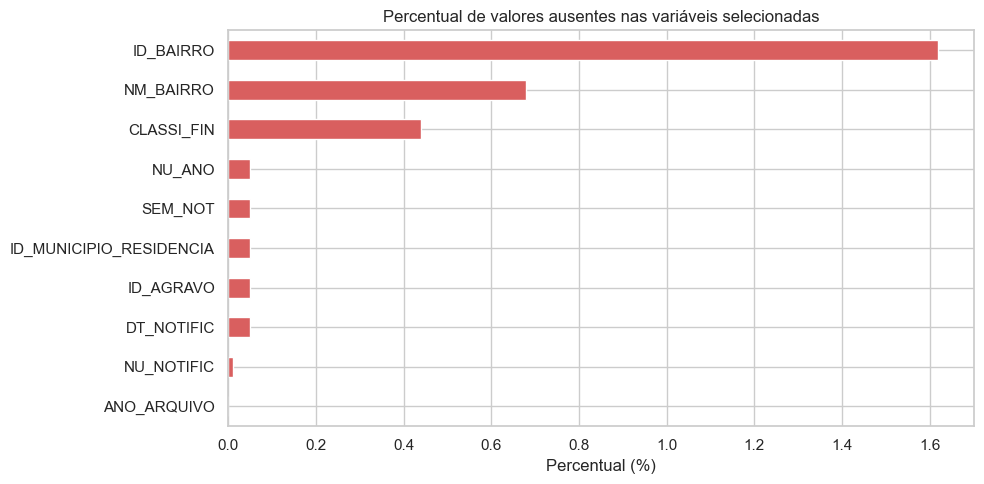

In [6]:
ax = qualidade["percentual_ausente"].sort_values().plot.barh(
    color="#d95f5f", figsize=(10, 5)
)
ax.set_title("Percentual de valores ausentes nas variáveis selecionadas")
ax.set_xlabel("Percentual (%)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 7. Limpeza, identidade e reconciliação das perdas

O número da notificação isolado não é tratado como chave universal. A auditoria usa o par **ano real da data de notificação + identificador** e distingue:

- cópias analiticamente idênticas, removidas globalmente mesmo quando aparecem em arquivos nominais diferentes;
- registros com o mesmo identificador e informações divergentes, preservados por falta de base para escolher uma versão;
- registros fora do ano nominal do arquivo, mantidos quando a data e o ano declarado concordam;
- linhas inválidas ou fora do território, contabilizadas antes da exclusão.

Também é produzido um cenário conservador de sensibilidade com no máximo um registro por ano real + identificador. Nenhum identificador individual é exportado nos relatórios de sensibilidade.

In [7]:
df = dengue.copy()
df["DT_NOTIFIC"] = datas_notificacao(df["DT_NOTIFIC"])
for c in ["ID_BAIRRO", "CLASSI_FIN"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["ID_AGRAVO"] = df.ID_AGRAVO.astype("string").str.strip().str.upper()
df["NU_NOTIFIC"] = codigo_inteiro(df["NU_NOTIFIC"])
df["ANO_NOTIFICACAO"] = df.DT_NOTIFIC.dt.year.astype("Int64")

agravo_nao_dengue = df.ID_AGRAVO.notna() & df.ID_AGRAVO.ne("A90")
if agravo_nao_dengue.any():
    raise ValueError("A fonte nominal de dengue contém outro agravo; revisar antes de prosseguir.")
perdas_agravo = df.loc[agravo_nao_dengue].groupby("ANO_ARQUIVO").size()
df = df.loc[~agravo_nao_dengue].copy()

campos = ["DT_NOTIFIC", "ID_BAIRRO", "NM_BAIRRO", "CLASSI_FIN", "ID_MUNICIPIO_RESIDENCIA", "ID_AGRAVO"]
# Cópia exata é definida pelos campos analíticos e pelo ID, sem usar o ano nominal do arquivo.
duplicadas = df.NU_NOTIFIC.notna() & df.duplicated(["NU_NOTIFIC"] + campos, keep="first")
perdas_dup = df.loc[duplicadas].groupby("ANO_ARQUIVO").size()
df = df.loc[~duplicadas].copy()

com_id = df.loc[df.NU_NOTIFIC.notna() & df.ANO_NOTIFICACAO.notna()].copy()
chaves_id = ["ANO_NOTIFICACAO", "NU_NOTIFIC"]
conflitos = com_id.groupby(chaves_id)[campos].nunique(dropna=False).gt(1).any(axis=1)
chaves_conflitantes = conflitos.loc[conflitos].reset_index()[chaves_id]
registros_divergentes = com_id.merge(chaves_conflitantes, on=chaves_id, how="inner")
resumo_conflitos = registros_divergentes.groupby("ANO_NOTIFICACAO").agg(
    ids_divergentes=("NU_NOTIFIC", "nunique"), registros_preservados=("NU_NOTIFIC", "size"))
resumo_conflitos.to_csv(REPORT_DIR/"ids_divergentes_resumo_por_ano.csv",encoding="utf-8")
df = df.merge(chaves_conflitantes.assign(ID_DIVERGENTE=True), on=chaves_id, how="left")
df["ID_DIVERGENTE"] = df.ID_DIVERGENTE.fillna(False).astype(bool)
df["EXCEDENTE_CENARIO_UM_POR_ID"] = False
mask_div = df.ID_DIVERGENTE
df.loc[mask_div,"EXCEDENTE_CENARIO_UM_POR_ID"] = df.loc[mask_div].groupby(chaves_id).cumcount().gt(0)
print("IDs-ano com registros analiticamente divergentes preservados:", int(conflitos.sum()))
display(resumo_conflitos)

fora_ano_arquivo = (df.loc[df.ANO_NOTIFICACAO.ne(df.ANO_ARQUIVO)]
    .groupby(["ANO_ARQUIVO","ANO_NOTIFICACAO"],dropna=False).size().rename("registros").reset_index())
fora_ano_arquivo.to_csv(REPORT_DIR/"registros_fora_ano_arquivo.csv",index=False,encoding="utf-8")

arquivo_geo = INPUT_DIR / "bairros.geojson"
if arquivo_geo.exists(): geo_bairros = json.loads(ler_local(arquivo_geo))
else: geo_bairros = json.loads(baixar(recurso_area("BAIRROS DO RECIFE", "GEOJSON")["url"]))
mapa_id_bairro = {int(f["properties"]["CBAIRRCODI"]) // 10: nome_padrao(f["properties"]["EBAIRRNOME"]) for f in geo_bairros["features"]}
df["BAIRRO"] = df["ID_BAIRRO"].map(mapa_id_bairro).fillna(df["NM_BAIRRO"].map(nome_padrao))
df.loc[df["BAIRRO"].isin(["", "IGNORADO", "NAO INFORMADO"]), "BAIRRO"] = pd.NA

municipio = codigo_inteiro(df.ID_MUNICIPIO_RESIDENCIA)
fora_recife = municipio.notna() & ~municipio.isin(["261160", "2611606"])
df["MUNICIPIO_RESIDENCIA_AUSENTE"] = municipio.isna()
perdas_municipio = df.loc[fora_recife].groupby("ANO_ARQUIVO").size()
df = df.loc[~fora_recife].copy()
invalidas = df.loc[df[["DT_NOTIFIC", "BAIRRO"]].isna().any(axis=1)]
df_limpo = df.drop(index=invalidas.index).copy()
df_limpo["DATA_SEMANA"] = inicio_semana(df_limpo["DT_NOTIFIC"])
iso = df_limpo["DATA_SEMANA"].dt.isocalendar()
df_limpo["ANO"], df_limpo["SEMANA"] = iso.year.astype(int), iso.week.astype(int)

qualidade_ano = relatorio_download.set_index("ano")[["registros"]].rename(columns={"registros":"lidos"})
qualidade_ano["duplicatas_identicas_globais"] = perdas_dup
qualidade_ano["agravo_nao_dengue"] = perdas_agravo
qualidade_ano["fora_recife"] = perdas_municipio
qualidade_ano["chaves_invalidas"] = invalidas.groupby("ANO_ARQUIVO").size()
qualidade_ano["validos"] = df_limpo.groupby("ANO_ARQUIVO").size()
qualidade_ano = qualidade_ano.fillna(0).astype(int)
assert (qualidade_ano.lidos == qualidade_ano.duplicatas_identicas_globais + qualidade_ano.agravo_nao_dengue + qualidade_ano.fora_recife + qualidade_ano.chaves_invalidas + qualidade_ano.validos).all()
qualidade_ano.to_csv(REPORT_DIR/"qualidade_por_ano.csv",encoding="utf-8")
display(qualidade_ano)

classificacao = df_limpo.groupby(["ANO_NOTIFICACAO","CLASSI_FIN"],dropna=False).size().rename("registros").reset_index()
classificacao.to_csv(REPORT_DIR/"classificacao_final_por_ano.csv",index=False,encoding="utf-8")
confirmada = df_limpo.CLASSI_FIN.isin([10,11,12])
sens_classificacao = df_limpo.assign(CONFIRMADA_10_11_12=confirmada).groupby("ANO_NOTIFICACAO").agg(
    notificacoes_total=("DT_NOTIFIC","size"), confirmadas_10_11_12=("CONFIRMADA_10_11_12","sum"),
    descartadas_5=("CLASSI_FIN",lambda s:s.eq(5).sum()), inconclusivas_8=("CLASSI_FIN",lambda s:s.eq(8).sum()),
    classificacao_ausente=("CLASSI_FIN",lambda s:s.isna().sum()), outros_codigos=("CLASSI_FIN",lambda s:(~s.isin([5,8,10,11,12]) & s.notna()).sum()))
sens_classificacao["confirmadas_pct"] = 100*sens_classificacao.confirmadas_10_11_12/sens_classificacao.notificacoes_total
sens_classificacao.to_csv(REPORT_DIR/"sensibilidade_classificacao_por_ano.csv",encoding="utf-8")
display(sens_classificacao)

sens_ids_ano = df_limpo.groupby("ANO_NOTIFICACAO").agg(
    notificacoes_preservadas=("DT_NOTIFIC","size"),
    notificacoes_cenario_um_por_id=("EXCEDENTE_CENARIO_UM_POR_ID",lambda s:(~s).sum()),
    registros_divergentes=("ID_DIVERGENTE","sum"))
sens_ids_ano["diferenca"] = sens_ids_ano.notificacoes_preservadas-sens_ids_ano.notificacoes_cenario_um_por_id
sens_ids_ano["diferenca_pct"] = 100*sens_ids_ano.diferenca/sens_ids_ano.notificacoes_preservadas
sens_ids_ano.to_csv(REPORT_DIR/"sensibilidade_ids_por_ano.csv",encoding="utf-8")
sens_ids_semana = df_limpo.groupby(["DATA_SEMANA","BAIRRO"]).agg(
    notificacoes_preservadas=("DT_NOTIFIC","size"),
    notificacoes_cenario_um_por_id=("EXCEDENTE_CENARIO_UM_POR_ID",lambda s:(~s).sum()))
sens_ids_semana["diferenca"] = sens_ids_semana.notificacoes_preservadas-sens_ids_semana.notificacoes_cenario_um_por_id
sens_ids_semana.loc[sens_ids_semana.diferenca.gt(0)].to_csv(REPORT_DIR/"sensibilidade_ids_bairro_semana.csv",encoding="utf-8")

print("IDs ausentes preservados:",int(df_limpo.NU_NOTIFIC.isna().sum()))
print("Alvo principal: todas as notificações A90 publicadas; classificação final é sensibilidade, não entrada.")
print("Município de residência ausente nos registros mantidos:",int(df_limpo.MUNICIPIO_RESIDENCIA_AUSENTE.sum()))
datas_por_arquivo = df_limpo.groupby("ANO_ARQUIVO").DT_NOTIFIC.agg(["min","max","count"])
datas_por_arquivo.to_csv(REPORT_DIR/"datas_por_arquivo.csv",encoding="utf-8")
datas_por_notificacao = df_limpo.groupby("ANO_NOTIFICACAO").DT_NOTIFIC.agg(["min","max","count"])
datas_por_notificacao.to_csv(REPORT_DIR/"datas_por_ano_notificacao.csv",encoding="utf-8")
display(datas_por_arquivo)
display(fora_ano_arquivo)

IDs-ano com registros analiticamente divergentes preservados: 787


C:\Users\beloa\AppData\Local\Temp\ipykernel_33320\2711419579.py:30: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["ID_DIVERGENTE"] = df.ID_DIVERGENTE.fillna(False).astype(bool)


,ids_divergentes,registros_preservados
ANO_NOTIFICACAO,,
2016,531,1071
2017,13,26
2018,12,24
2019,79,160
2020,23,48
2021,29,58
2022,7,14
2023,11,24
2024,80,173


,lidos,duplicatas_identicas_globais,agravo_nao_dengue,fora_recife,chaves_invalidas,validos
ano,,,,,,
2016,18612,0,0,0,338,18274
2017,2454,0,0,0,1,2453
2018,2687,0,0,0,8,2679
2019,7308,0,0,0,81,7227
2020,3540,1,0,0,10,3529
2021,10898,0,0,0,0,10898
2022,2906,3,0,0,27,2876
2023,3523,0,0,0,1,3522
2024,10548,0,0,0,0,10548


,notificacoes_total,confirmadas_10_11_12,descartadas_5,inconclusivas_8,classificacao_ausente,outros_codigos,confirmadas_pct
ANO_NOTIFICACAO,,,,,,,
2016,18200,11932,4825,1415,23,5,65.560440
2017,2487,977,1506,4,0,0,39.284278
2018,2636,1189,1439,8,0,0,45.106222
2019,7284,4075,2621,588,0,0,55.944536
2020,3555,1501,1926,127,1,0,42.222222
2021,10898,7397,3500,1,0,0,67.874839
2022,2876,1353,1522,1,0,0,47.044506
2023,3522,1430,2009,82,1,0,40.601931
2024,10548,2607,7941,0,0,0,24.715586


IDs ausentes preservados: 0
Alvo principal: todas as notificações A90 publicadas; classificação final é sensibilidade, não entrada.
Município de residência ausente nos registros mantidos: 0


,min,max,count
ANO_ARQUIVO,,,
2016,2016-01-03,2018-04-16,18274
2017,2017-01-02,2019-07-23,2453
2018,2018-01-02,2020-02-04,2679
2019,2019-01-02,2020-02-06,7227
2020,2020-01-01,2020-12-30,3529
2021,2021-01-01,2021-12-31,10898
2022,2022-01-03,2022-12-31,2876
2023,2023-01-01,2023-12-30,3522
2024,2024-01-02,2024-12-31,10548


,ANO_ARQUIVO,ANO_NOTIFICACAO,registros
0,2016,2017,73
1,2016,2018,1
2,2017,2018,37
3,2017,2019,2
4,2018,2019,80
5,2018,2020,1
6,2019,2020,25


## 8. Contagem de notificações por bairro e semana

Uma linha válida original é um registro publicado de notificação A90; uma linha agregada é um bairro em uma semana. A variável principal passa a se chamar `NOTIFICACOES_SEMANAIS`, removendo a ambiguidade com casos confirmados.

A análise de classificação final é mantida em relatório separado. Ela não define o alvo primário porque essa informação pode ser encerrada ou revisada depois da semana que se pretende prever.

In [8]:
notificacoes_semanais = df_limpo.groupby(["DATA_SEMANA","BAIRRO"],as_index=False).size().rename(columns={"size":"REGISTROS_OBSERVADOS"})
assert notificacoes_semanais.REGISTROS_OBSERVADOS.sum()==len(df_limpo)
display(notificacoes_semanais.head())

,DATA_SEMANA,BAIRRO,REGISTROS_OBSERVADOS
0,2015-12-28,AFOGADOS,1
1,2015-12-28,BARRO,1
2,2015-12-28,BOA VIAGEM,1
3,2015-12-28,ILHA DO RETIRO,1
4,2015-12-28,MUSTARDINHA,1


## 9. População por bairro - Censo 2022/IBGE

In [9]:
local_pop = INPUT_DIR / "populacao_bairros.csv"
if local_pop.exists():
    pop_recife = pd.read_csv(io.BytesIO(ler_local(local_pop)))
    exigidas = {"BAIRRO", "POPULACAO_2022", "AREA_KM2_IBGE"}
    if not exigidas.issubset(pop_recife): raise ValueError(f"População local deve conter {exigidas}")
    pop_recife = pop_recife[list(sorted(exigidas))].copy()
else:
    URL_POPULACAO = "https://ftp.ibge.gov.br/Censos/Censo_Demografico_2022/Agregados_por_Setores_Censitarios/Agregados_por_Bairro_xlsx/Agregados_por_bairros_basico_BR_20260520.zip"
    zip_local = INPUT_DIR / "populacao_ibge.zip"
    conteudo_zip = ler_local(zip_local) if zip_local.exists() else baixar(URL_POPULACAO)
    with zipfile.ZipFile(io.BytesIO(conteudo_zip)) as z:
        membros = [x for x in z.namelist() if x.lower().endswith(".xlsx")]
        if len(membros)!=1: raise ValueError("ZIP IBGE sem XLSX único: conferir a seleção.")
        populacao_br = pd.read_excel(io.BytesIO(z.read(membros[0])))
    pop_recife = populacao_br.loc[populacao_br.NM_UF.map(nome_padrao).eq("PERNAMBUCO") & populacao_br.NM_MUN.map(nome_padrao).eq("RECIFE")].copy()
    pop_recife = pop_recife.rename(columns={"v0001":"POPULACAO_2022","AREA_KM2":"AREA_KM2_IBGE"})[["BAIRRO" if "BAIRRO" in pop_recife else "NM_BAIRRO", "POPULACAO_2022", "AREA_KM2_IBGE"]]
    pop_recife = pop_recife.rename(columns={"NM_BAIRRO":"BAIRRO"})
pop_recife["BAIRRO"] = pop_recife.BAIRRO.map(nome_padrao)
# Compatibilizar o nome IBGE com a malha e a tabela RPA da Prefeitura.
# As duas fontes têm 94 bairros; este é o único nome divergente.
pop_recife["BAIRRO"] = pop_recife["BAIRRO"].replace({"SITIO DOS PINTOS - SAO BRAS":"SITIO DOS PINTOS"})
for c in ["POPULACAO_2022", "AREA_KM2_IBGE"]: pop_recife[c] = pd.to_numeric(pop_recife[c], errors="coerce")
assert pop_recife.POPULACAO_2022.gt(0).all() and pop_recife.AREA_KM2_IBGE.gt(0).all()
pop_recife["DENSIDADE_HAB_KM2"] = pop_recife.POPULACAO_2022 / pop_recife.AREA_KM2_IBGE
print("Bairros:",len(pop_recife),"População:",pop_recife.POPULACAO_2022.sum())
if len(pop_recife)!=94: print("ATENÇÃO: malha diferente dos 94 bairros esperados; conferir a fonte antes de concluir.")
display(pop_recife.head())

Bairros: 94 População: 1488920


,BAIRRO,POPULACAO_2022,AREA_KM2_IBGE,DENSIDADE_HAB_KM2
4281,RECIFE,541,1.235592,437.846797
4282,SANTO AMARO,27103,3.377832,8023.785433
4283,BOA VISTA,13147,1.769746,7428.748403
4284,SOLEDADE,2081,0.323412,6434.512984
4285,SANTO ANTONIO,447,0.517712,863.415075


## 10. RPA e geometria dos bairros - Prefeitura do Recife

In [10]:
local_rpa = INPUT_DIR / "bairros_rpa.csv"
rpa = ler_csv_bytes(ler_local(local_rpa) if local_rpa.exists() else baixar(recurso_area("BAIRROS E RPAS", "CSV")["url"]))
if not {"BAIRRO","RPA"}.issubset(rpa): raise ValueError("A tabela RPA precisa das colunas BAIRRO e RPA.")
rpa["BAIRRO"] = rpa.BAIRRO.map(nome_padrao)
rpa = rpa[["BAIRRO","RPA"]].drop_duplicates()
assert not rpa.BAIRRO.duplicated().any(), "RPA ambígua por bairro"
display(rpa.head())

,BAIRRO,RPA
0,AFLITOS,3
1,AFOGADOS,5
2,AGUA FRIA,2
3,ALTO DO MANDU,3
4,ALTO JOSE BONIFACIO,3


## 11. Painel semanal e hipótese de cobertura

O preenchimento com zero significa **nenhuma notificação encontrada no recurso oficial dentro de uma semana considerada coberta**. Não significa ausência real de infecção, de subnotificação ou de falha do sistema.

A execução de referência usa recursos anuais de 2016–2025. As datas reais, linhas inválidas, registros fora do ano nominal e semanas de fronteira são auditados. Uma semana só recebe zero quando seus sete dias pertencem aos intervalos configurados e os anos civis envolvidos foram adquiridos; semanas incompletas permanecem ausentes.

A proporção de bairro-semanas iguais a zero é exportada por ano para tornar a hipótese verificável. Na AV2, essa limitação deve acompanhar métricas e conclusões.

In [11]:
assert not pop_recife.BAIRRO.duplicated().any(), "Bairros duplicados no IBGE"
assert pop_recife.POPULACAO_2022.gt(0).all() and pop_recife.AREA_KM2_IBGE.gt(0).all()
fora = notificacoes_semanais.loc[~notificacoes_semanais.BAIRRO.isin(pop_recife.BAIRRO)]
fora.to_csv(REPORT_DIR / "registros_fora_malha_agregados.csv", index=False)
print("Notificações fora da malha:", int(fora.REGISTROS_OBSERVADOS.sum()))
if INTERVALOS_COBERTURA_CONFIRMADA and not JUSTIFICATIVA_COBERTURA.strip():
    raise ValueError("Registre a justificativa documental da cobertura em config_local.json.")
inicio = pd.Timestamp(f"{min(ANOS)}-01-01")
fim = pd.Timestamp(f"{max(ANOS)}-12-31")
primeira = inicio - pd.Timedelta(days=inicio.weekday())
calendario = pd.DataFrame({"DATA_SEMANA": pd.date_range(primeira, fim, freq="W-MON")})
calendario["COBERTURA_DENGUE"] = calendario.DATA_SEMANA.map(semana_coberta)
iso = calendario.DATA_SEMANA.dt.isocalendar()
calendario["ANO"], calendario["SEMANA"] = iso.year.astype(int), iso.week.astype(int)
# Conferir também se os arquivos dos anos civis que cobrem cada semana foram adquiridos.
anos_lidos = set(relatorio_download.ano)
calendario["COBERTURA_DENGUE"] &= calendario.DATA_SEMANA.map(lambda d: all(x.year in anos_lidos for x in pd.date_range(d, periods=7)))
calendario.to_csv(REPORT_DIR / "cobertura_semanal.csv", index=False)
grade = pop_recife[["BAIRRO"]].merge(calendario, how="cross")
base = (grade.merge(notificacoes_semanais, on=["DATA_SEMANA", "BAIRRO"], how="left", validate="one_to_one")
        .merge(pop_recife, on="BAIRRO", how="left", validate="many_to_one")
        .merge(rpa, on="BAIRRO", how="left", validate="many_to_one"))
base["NOTIFICACOES_SEMANAIS"] = base.REGISTROS_OBSERVADOS.fillna(0).where(base.COBERTURA_DENGUE)
base["INCIDENCIA_100MIL"] = base.NOTIFICACOES_SEMANAIS / base.POPULACAO_2022 * 100_000
assert not base.duplicated(["BAIRRO", "DATA_SEMANA"]).any()
print("Semanas cobertas pela hipótese operacional:", int(calendario.COBERTURA_DENGUE.sum()))
if not calendario.COBERTURA_DENGUE.any():
    raise ValueError("Cobertura ainda não aprovada. Confira relatorios/aquisicao_por_ano.csv e qualidade_por_ano.csv; preencha INTERVALOS_COBERTURA_CONFIRMADA na configuração e reexecute. Nenhum zero ou resultado climático foi validado.")
display(base.head())
perdas_territorio = pd.DataFrame({"indicador":["notificacoes_validas", "fora_malha", "no_painel_observado", "sem_rpa"],
 "valor":[len(df_limpo),int(fora.REGISTROS_OBSERVADOS.sum()),int(base.REGISTROS_OBSERVADOS.sum()),int(base.RPA.isna().sum())]})
assert len(df_limpo)==int(fora.REGISTROS_OBSERVADOS.sum())+int(base.REGISTROS_OBSERVADOS.sum())
perdas_territorio.to_csv(REPORT_DIR/"integracao_territorial.csv",index=False)

auditoria_zeros = (base.loc[base.COBERTURA_DENGUE].groupby("ANO").agg(
    bairro_semanas=("BAIRRO","size"), semanas=("DATA_SEMANA","nunique"), bairros=("BAIRRO","nunique"),
    bairro_semanas_zero=("NOTIFICACOES_SEMANAIS",lambda s:s.eq(0).sum()),
    notificacoes=("NOTIFICACOES_SEMANAIS","sum")))
auditoria_zeros["zeros_pct"] = 100*auditoria_zeros.bairro_semanas_zero/auditoria_zeros.bairro_semanas
auditoria_zeros.to_csv(REPORT_DIR/"auditoria_zeros_por_ano.csv",encoding="utf-8")
display(auditoria_zeros)


Notificações fora da malha: 49


Semanas cobertas pela hipótese operacional: 521


,BAIRRO,DATA_SEMANA,COBERTURA_DENGUE,ANO,SEMANA,REGISTROS_OBSERVADOS,POPULACAO_2022,AREA_KM2_IBGE,DENSIDADE_HAB_KM2,RPA,NOTIFICACOES_SEMANAIS,INCIDENCIA_100MIL
0,RECIFE,2015-12-28,False,2015,53,NaN,541,1.235592,437.846797,1,NaN,NaN
1,RECIFE,2016-01-04,True,2016,1,2.0,541,1.235592,437.846797,1,2.0,369.685767
2,RECIFE,2016-01-11,True,2016,2,3.0,541,1.235592,437.846797,1,3.0,554.528651
3,RECIFE,2016-01-18,True,2016,3,12.0,541,1.235592,437.846797,1,12.0,2218.114603
4,RECIFE,2016-01-25,True,2016,4,15.0,541,1.235592,437.846797,1,15.0,2772.643253


,bairro_semanas,semanas,bairros,bairro_semanas_zero,notificacoes,zeros_pct
ANO,,,,,,
2016,4888,52,94,2145,18185.0,43.882979
2017,4888,52,94,3486,2486.0,71.317512
2018,4888,52,94,3378,2633.0,69.108020
2019,4888,52,94,2606,7246.0,53.314239
2020,4982,53,94,3524,3582.0,70.734645
2021,4888,52,94,2579,10890.0,52.761866
2022,4888,52,94,3324,2878.0,68.003273
2023,4888,52,94,3038,3520.0,62.152209
2024,4888,52,94,2125,10537.0,43.473813


## 12. Dados climáticos do INMET

Os ZIPs anuais oficiais contêm as estações automáticas do Brasil. O código seleciona somente **A301 — Recife**, registra as fontes e resume medições horárias por semana.

A série válida usada na coorte comum cobre 2016–2021. A inspeção dos arquivos oficiais de 2022 e 2023 encontrou as colunas de chuva, temperatura e umidade sem medições para A301; ausência não é convertida em zero. O arquivo de 2022 foi novamente conferido na revisão e contém 8.760 horas com todas as medidas meteorológicas vazias. Não se substitui A301 por estação distante sem estudo de representatividade.

As janelas de até oito semanas são definidas antes da modelagem. A justificativa é biológica: em condições favoráveis, o desenvolvimento do ovo ao mosquito adulto pode levar aproximadamente 7–10 dias; a reprodução do vírus no mosquito e a manifestação no ser humano acrescentam outros intervalos, além do atraso de atendimento e notificação. Isso justifica examinar efeitos distribuídos, mas não garante uma associação forte.

> Os dados automáticos são brutos e podem conter `9999`, nulos ou falhas de sensor. Cada variável precisa atingir o limiar semanal configurado; chuva continua sendo soma observada, sem extrapolação das horas ausentes.


In [12]:
def escolher_coluna(colunas, termos):
    return next((c for c in colunas if all(t in nome_padrao(c) for t in termos)), None)

def ler_csv_inmet(payload):
    texto = payload.decode("utf-8-sig", errors="replace")
    if "\ufffd" in texto: texto = payload.decode("latin-1")
    linhas = texto.splitlines()
    cabecalho = next((i for i,l in enumerate(linhas) if "DATA" in nome_padrao(l.split(";")[0]) and ";" in l and "HORA" in nome_padrao(l)),None)
    if cabecalho is None: raise ValueError("Cabeçalho horário do INMET não encontrado.")
    d = pd.read_csv(io.StringIO("\n".join(linhas[cabecalho:])), sep=";", decimal=",", dtype=str)
    data = escolher_coluna(d.columns,["DATA"]); hora = escolher_coluna(d.columns,["HORA"])
    medidas = {"PRECIPITACAO_MM":escolher_coluna(d.columns,["PRECIPITACAO","TOTAL"]),
     "TEMPERATURA_C":escolher_coluna(d.columns,["TEMPERATURA DO AR","BULBO SECO"]),
     "UMIDADE_PCT":escolher_coluna(d.columns,["UMIDADE RELATIVA DO AR","HORARIA"])}
    if not data or not hora or not all(medidas.values()): raise ValueError("Colunas do INMET não reconhecidas.")
    h = d[hora].astype(str).str.extract(r"^(\d{2})(?:\d{2}|:\d{2})?",expand=False)
    t = pd.DataFrame({"DATA_HORA_UTC":datas_notificacao(d[data]) + pd.to_timedelta(pd.to_numeric(h,errors="coerce"),unit="h")})
    for destino,origem in medidas.items():
        t[destino] = pd.to_numeric(d[origem].str.replace(",",".",regex=False),errors="coerce")
    return t

def carregar_inmet_recife(anos=None, estacao="A301"):
    anos = ANOS_CLIMA if anos is None else anos
    if CSV_CLIMA_LOCAL.exists():
        local = pd.read_csv(io.BytesIO(ler_local(CSV_CLIMA_LOCAL)))
        exigidas = ["DATA_HORA_UTC","PRECIPITACAO_MM","TEMPERATURA_C","UMIDADE_PCT"]
        if not set(exigidas).issubset(local): raise ValueError(f"Clima local deve conter {exigidas}")
        return local[exigidas].copy()
    partes, log = [], []
    for ano in anos:
        csv_local = INPUT_DIR / f"INMET_A301_{ano}.csv"
        if csv_local.exists():
            partes.append(ler_csv_inmet(ler_local(csv_local))); log.append({"ano":ano,"status":"csv_oficial_local"})
            continue
        zip_local = INPUT_DIR / f"INMET_{ano}.zip"
        payload = ler_local(zip_local) if zip_local.exists() else baixar(f"https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip")
        with zipfile.ZipFile(io.BytesIO(payload)) as z:
            membros = [x for x in z.namelist() if re.search(rf"(?:^|_){estacao}(?:_|\.)",nome_padrao(Path(x).name)) and x.lower().endswith(".csv")]
            if not membros:
                log.append({"ano":ano,"status":"estacao_nao_encontrada"})
            else:
                # Suporta um ano dividido em vários CSVs; horas repetidas serão conferidas depois.
                for m in membros: partes.append(ler_csv_inmet(z.read(m)))
                log.append({"ano":ano,"status":"encontrada","arquivos":len(membros)})
        pd.DataFrame(log).to_csv(REPORT_DIR/"aquisicao_clima.csv",index=False)
    pd.DataFrame(log).to_csv(REPORT_DIR/"aquisicao_clima.csv",index=False)
    if not partes: raise ValueError("Nenhuma observação da A301 disponível. Não é possível analisar a hipótese climática.")
    return pd.concat(partes,ignore_index=True)

**12.1 Download dos anos e seleção da estação**

Esta célula é separada porque concentra a etapa mais demorada. O log mostra claramente quais anos possuem a estação A301 no arquivo anual. Ausência de uma estação em determinado ano é mantida como limitação, nunca inventada ou imputada sem justificativa.

In [13]:
clima_horario = carregar_inmet_recife()
clima_horario["DATA_HORA_UTC"] = pd.to_datetime(clima_horario.DATA_HORA_UTC, utc=True, errors="coerce")
clima_horario = clima_horario.dropna(subset=["DATA_HORA_UTC"]).sort_values("DATA_HORA_UTC")
medidas = ["PRECIPITACAO_MM", "TEMPERATURA_C", "UMIDADE_PCT"]
conflitos_hora = clima_horario.groupby("DATA_HORA_UTC")[medidas].nunique(dropna=False).gt(1).any(axis=1)
if conflitos_hora.any(): raise ValueError("Observações climáticas conflitantes para a mesma hora; revisar fontes.")
clima_horario = clima_horario.drop_duplicates("DATA_HORA_UTC")
for c in ["PRECIPITACAO_MM", "TEMPERATURA_C", "UMIDADE_PCT"]:
    clima_horario[c] = pd.to_numeric(clima_horario[c], errors="coerce")
    clima_horario.loc[clima_horario[c].abs().ge(9999), c] = np.nan
clima_horario.loc[clima_horario.PRECIPITACAO_MM.lt(0), "PRECIPITACAO_MM"] = np.nan
clima_horario.loc[~clima_horario.UMIDADE_PCT.between(0,100), "UMIDADE_PCT"] = np.nan
clima_horario["DATA_LOCAL"] = clima_horario.DATA_HORA_UTC.dt.tz_convert("America/Recife").dt.tz_localize(None).dt.normalize()
clima_horario["DATA_SEMANA"] = inicio_semana(clima_horario.DATA_LOCAL)
display(clima_horario.head())
# Contar linhas não é comprovar medições: conferir valores válidos por ano UTC.
qualidade_clima = clima_horario.assign(ANO_UTC=clima_horario.DATA_HORA_UTC.dt.year).groupby("ANO_UTC").agg(
    linhas_horarias=("DATA_HORA_UTC","size"),chuva_valida=("PRECIPITACAO_MM","count"),
    temperatura_valida=("TEMPERATURA_C","count"),umidade_valida=("UMIDADE_PCT","count"))
qualidade_clima.to_csv(REPORT_DIR/"qualidade_clima_por_ano.csv")
display(qualidade_clima)
if qualidade_clima[["chuva_valida","temperatura_valida","umidade_valida"]].eq(0).any(axis=None):
    print("Há ano/variável sem medições válidas; não equivale a ausência de chuva ou estabilidade do clima.")


,DATA_HORA_UTC,PRECIPITACAO_MM,TEMPERATURA_C,UMIDADE_PCT,DATA_LOCAL,DATA_SEMANA
0,2016-01-01 00:00:00+00:00,0.0,25.7,70.0,2015-12-31,2015-12-28
1,2016-01-01 01:00:00+00:00,0.0,25.2,75.0,2015-12-31,2015-12-28
2,2016-01-01 02:00:00+00:00,0.0,25.0,78.0,2015-12-31,2015-12-28
3,2016-01-01 03:00:00+00:00,0.0,25.0,78.0,2016-01-01,2015-12-28
4,2016-01-01 04:00:00+00:00,0.0,24.3,78.0,2016-01-01,2015-12-28


,linhas_horarias,chuva_valida,temperatura_valida,umidade_valida
ANO_UTC,,,,
2016,8784,8507,8507,8502
2017,8760,8226,8227,8087
2018,8760,8289,8289,8289
2019,8760,8755,8755,8755
2020,8784,8776,8776,8776
2021,8760,7492,7551,7442


In [14]:
clima_semanal = clima_horario.groupby("DATA_SEMANA").agg(
    PRECIPITACAO_SEMANAL_MM=("PRECIPITACAO_MM", lambda s:s.sum(min_count=1)),
    TEMPERATURA_MEDIA_C=("TEMPERATURA_C", "mean"), UMIDADE_MEDIA_PCT=("UMIDADE_PCT", "mean"),
    HORAS_CHUVA=("PRECIPITACAO_MM", "count"), HORAS_TEMPERATURA=("TEMPERATURA_C", "count"),
    HORAS_UMIDADE=("UMIDADE_PCT", "count"))
# Reindexar antes das janelas: uma linha sempre corresponde a sete dias consecutivos.
clima_semanal = clima_semanal.reindex(pd.DatetimeIndex(calendario.DATA_SEMANA, name="DATA_SEMANA"))
for medida, horas in [("PRECIPITACAO_SEMANAL_MM","HORAS_CHUVA"), ("TEMPERATURA_MEDIA_C","HORAS_TEMPERATURA"), ("UMIDADE_MEDIA_PCT","HORAS_UMIDADE")]:
    cobertura = "COBERTURA_" + horas.removeprefix("HORAS_")
    clima_semanal[cobertura] = clima_semanal[horas].fillna(0) / 168
    clima_semanal.loc[clima_semanal[cobertura] < COBERTURA_MINIMA_CLIMA, medida] = np.nan

# Atributos climáticos definidos a priori: efeitos defasados de 1–8 semanas e janelas 2/4/8.
# Nenhum atraso é escolhido por olhar validação ou teste.
clima_base = {
    "PRECIPITACAO": ("PRECIPITACAO_SEMANAL_MM", "MM"),
    "TEMPERATURA": ("TEMPERATURA_MEDIA_C", "C"),
    "UMIDADE": ("UMIDADE_MEDIA_PCT", "PCT"),
}
clima_lags = []
for prefixo, (origem, sufixo) in clima_base.items():
    for atraso in range(1, 9):
        coluna = f"{prefixo}_LAG_{atraso}_{sufixo}"
        clima_semanal[coluna] = clima_semanal[origem].shift(atraso)
        clima_lags.append(coluna)

clima_janelas = []
for janela in [2, 4, 8]:
    chuva = f"CHUVA_{janela}S_MM"
    temperatura = f"TEMPERATURA_MEDIA_{janela}S_C"
    umidade = f"UMIDADE_MEDIA_{janela}S_PCT"
    clima_semanal[chuva] = clima_semanal.PRECIPITACAO_SEMANAL_MM.rolling(janela, min_periods=janela).sum()
    clima_semanal[temperatura] = clima_semanal.TEMPERATURA_MEDIA_C.rolling(janela, min_periods=janela).mean()
    clima_semanal[umidade] = clima_semanal.UMIDADE_MEDIA_PCT.rolling(janela, min_periods=janela).mean()
    clima_janelas.extend([chuva, temperatura, umidade])

clima_atual = ["PRECIPITACAO_SEMANAL_MM", "TEMPERATURA_MEDIA_C", "UMIDADE_MEDIA_PCT"]
clima_features_modelo = clima_atual + clima_lags + clima_janelas

sens_limiar = []
for limiar in [0.80, 0.90, 0.95]:
    atual_ok = clima_semanal[["COBERTURA_CHUVA","COBERTURA_TEMPERATURA","COBERTURA_UMIDADE"]].ge(limiar).all(axis=1)
    janela_8s_ok = clima_semanal[["COBERTURA_CHUVA","COBERTURA_TEMPERATURA","COBERTURA_UMIDADE"]].ge(limiar).all(axis=1).rolling(8,min_periods=8).sum().eq(8)
    sens_limiar.append({"limiar":limiar,"semanas_clima_atual_completo":int(atual_ok.sum()),
                         "semanas_clima_e_janela_8s_completos":int((atual_ok & janela_8s_ok).sum())})
sensibilidade_limiar_clima = pd.DataFrame(sens_limiar)
sensibilidade_limiar_clima.to_csv(REPORT_DIR/"sensibilidade_limiar_clima.csv",index=False,encoding="utf-8")
display(sensibilidade_limiar_clima)
clima_semanal = clima_semanal.reset_index()
clima_semanal.to_csv(REPORT_DIR / "clima_semanal_cobertura.csv", index=False)
base = base.merge(clima_semanal, on="DATA_SEMANA", how="left", validate="many_to_one")
display(base.head())


,limiar,semanas_clima_atual_completo,semanas_clima_e_janela_8s_completos
0,0.80,288,236
1,0.90,279,222
2,0.95,277,217


,BAIRRO,DATA_SEMANA,COBERTURA_DENGUE,ANO,SEMANA,REGISTROS_OBSERVADOS,POPULACAO_2022,AREA_KM2_IBGE,DENSIDADE_HAB_KM2,RPA,NOTIFICACOES_SEMANAIS,INCIDENCIA_100MIL,PRECIPITACAO_SEMANAL_MM,TEMPERATURA_MEDIA_C,UMIDADE_MEDIA_PCT,HORAS_CHUVA,HORAS_TEMPERATURA,HORAS_UMIDADE,COBERTURA_CHUVA,COBERTURA_TEMPERATURA,COBERTURA_UMIDADE,PRECIPITACAO_LAG_1_MM,PRECIPITACAO_LAG_2_MM,PRECIPITACAO_LAG_3_MM,PRECIPITACAO_LAG_4_MM,PRECIPITACAO_LAG_5_MM,PRECIPITACAO_LAG_6_MM,PRECIPITACAO_LAG_7_MM,PRECIPITACAO_LAG_8_MM,TEMPERATURA_LAG_1_C,TEMPERATURA_LAG_2_C,TEMPERATURA_LAG_3_C,TEMPERATURA_LAG_4_C,TEMPERATURA_LAG_5_C,TEMPERATURA_LAG_6_C,TEMPERATURA_LAG_7_C,TEMPERATURA_LAG_8_C,UMIDADE_LAG_1_PCT,UMIDADE_LAG_2_PCT,UMIDADE_LAG_3_PCT,UMIDADE_LAG_4_PCT,UMIDADE_LAG_5_PCT,UMIDADE_LAG_6_PCT,UMIDADE_LAG_7_PCT,UMIDADE_LAG_8_PCT,CHUVA_2S_MM,TEMPERATURA_MEDIA_2S_C,UMIDADE_MEDIA_2S_PCT,CHUVA_4S_MM,TEMPERATURA_MEDIA_4S_C,UMIDADE_MEDIA_4S_PCT,CHUVA_8S_MM,TEMPERATURA_MEDIA_8S_C,UMIDADE_MEDIA_8S_PCT
0,RECIFE,2015-12-28,False,2015,53,NaN,541,1.235592,437.846797,1,NaN,NaN,NaN,NaN,NaN,75.0,75.0,75.0,0.446429,0.446429,0.446429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,RECIFE,2016-01-04,True,2016,1,2.0,541,1.235592,437.846797,1,2.0,369.685767,32.0,27.047561,73.926829,164.0,164.0,164.0,0.976190,0.976190,0.976190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,RECIFE,2016-01-11,True,2016,2,3.0,541,1.235592,437.846797,1,3.0,554.528651,13.0,27.277381,74.321429,168.0,168.0,168.0,1.000000,1.000000,1.000000,32.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.047561,NaN,NaN,NaN,NaN,NaN,NaN,NaN,73.926829,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45.0,27.162471,74.124129,NaN,NaN,NaN,NaN,NaN,NaN
3,RECIFE,2016-01-18,True,2016,3,12.0,541,1.235592,437.846797,1,12.0,2218.114603,57.0,26.696429,76.422619,168.0,168.0,168.0,1.000000,1.000000,1.000000,13.0,32.0,NaN,NaN,NaN,NaN,NaN,NaN,27.277381,27.047561,NaN,NaN,NaN,NaN,NaN,NaN,74.321429,73.926829,NaN,NaN,NaN,NaN,NaN,NaN,70.0,26.986905,75.372024,NaN,NaN,NaN,NaN,NaN,NaN
4,RECIFE,2016-01-25,True,2016,4,15.0,541,1.235592,437.846797,1,15.0,2772.643253,15.2,26.660479,70.868263,167.0,167.0,167.0,0.994048,0.994048,0.994048,57.0,13.0,32.0,NaN,NaN,NaN,NaN,NaN,26.696429,27.277381,27.047561,NaN,NaN,NaN,NaN,NaN,76.422619,74.321429,73.926829,NaN,NaN,NaN,NaN,NaN,72.2,26.678454,73.645441,117.2,26.920462,73.884785,NaN,NaN,NaN


## 13. Feature engineering — regras e disponibilidade
Previsão proposta: ao encerrar a semana t, estimar casos notificados em t+1. É um estudo retrospectivo: atrasos e revisões ainda podem limitar uso real.

| Variável | Cálculo | Por que criar / cuidados |
|---|---|---|
| NOTIFICACOES_SEMANAIS | Casos notificados A90 na semana t com cobertura | Estado recente; não são necessariamente confirmados |
| NOTIFICACOES_LAG_1…4 | Contagem em t−1…t−4 por bairro | Histórico auxiliar e baseline; calendário contínuo |
| MEDIA_NOTIFICACOES_4S | Média de t−4…t−1 | Tendência recente sem incluir a semana atual |
| PRECIPITACAO / TEMPERATURA / UMIDADE_LAG_1…8 | Medida climática de t−1…t−8 | Captar atrasos biologicamente plausíveis sem escolher lags pelo teste |
| CHUVA_2S / 4S / 8S | Soma das semanas terminando em t | Disponibilidade acumulada de água; exige janela completa |
| TEMPERATURA_MEDIA_2S / 4S / 8S | Média das semanas terminando em t | Condição térmica acumulada |
| UMIDADE_MEDIA_2S / 4S / 8S | Média das semanas terminando em t | Condição de umidade acumulada |
| MES / TRIMESTRE | Data de início da semana | Descrição da sazonalidade; evitar redundância |
| SEMANA_SIN / SEMANA_COS | Seno/cosseno do ciclo anual | Continuidade na virada do ano |
| DENSIDADE_HAB_KM2 | População/área | Contexto territorial; Censo 2022 é aproximação histórica |
| INCIDENCIA_100MIL | Notificações/população × 100 mil | Comparação territorial; descritiva no conjunto inicial |
| NOTIFICACOES_PROXIMA_SEMANA | Contagem em t+1 do mesmo bairro | **Alvo; nunca entrada nem escalonado** |

Bairro e RPA são categorias. Identificadores e classificação final não são entradas. Todas as janelas climáticas terminam em t e estão disponíveis ao final da semana; nenhuma usa clima futuro. População e dados consolidados são aproximações retrospectivas.


In [15]:
base = base.sort_values(["BAIRRO", "DATA_SEMANA"]).reset_index(drop=True)
assert base.groupby("BAIRRO").DATA_SEMANA.diff().dropna().eq(pd.Timedelta(days=7)).all()
base["MES"] = base.DATA_SEMANA.dt.month
base["TRIMESTRE"] = base.DATA_SEMANA.dt.quarter
base["PERIODO_CHUVOSO"] = base.MES.between(3,8).astype(int)
fase = 2*np.pi*(base.DATA_SEMANA.dt.dayofyear - 1)/365.2425
base["SEMANA_SIN"], base["SEMANA_COS"] = np.sin(fase), np.cos(fase)
for atraso in range(1,5):
    base[f"NOTIFICACOES_LAG_{atraso}"] = base.groupby("BAIRRO").NOTIFICACOES_SEMANAIS.shift(atraso)
base["MEDIA_NOTIFICACOES_4S"] = base.groupby("BAIRRO").NOTIFICACOES_SEMANAIS.transform(lambda s:s.shift(1).rolling(4,min_periods=4).mean())
base["NOTIFICACOES_PROXIMA_SEMANA"] = base.groupby("BAIRRO").NOTIFICACOES_SEMANAIS.shift(-1)
base["DATA_ALVO"] = base.DATA_SEMANA + pd.Timedelta(days=7)
features_historicas = ["NOTIFICACOES_LAG_1", "NOTIFICACOES_LAG_2", "NOTIFICACOES_LAG_3", "NOTIFICACOES_LAG_4", "MEDIA_NOTIFICACOES_4S"]
features_criadas = features_historicas + clima_lags + clima_janelas + ["SEMANA_SIN", "SEMANA_COS", "DENSIDADE_HAB_KM2", "INCIDENCIA_100MIL"]
display(base[features_criadas].describe().T)


,count,mean,std,min,25%,50%,75%,max
NOTIFICACOES_LAG_1,48974.0,1.451321,4.093973,0.000000,0.000000,0.000000,1.000000,126.000000
NOTIFICACOES_LAG_2,48880.0,1.453253,4.097482,0.000000,0.000000,0.000000,1.000000,126.000000
NOTIFICACOES_LAG_3,48786.0,1.453757,4.100636,0.000000,0.000000,0.000000,1.000000,126.000000
NOTIFICACOES_LAG_4,48692.0,1.454120,4.103757,0.000000,0.000000,0.000000,1.000000,126.000000
MEDIA_NOTIFICACOES_4S,48692.0,1.440478,3.659821,0.000000,0.000000,0.500000,1.250000,93.000000
PRECIPITACAO_LAG_1_MM,26790.0,36.824561,44.353423,0.000000,6.800000,22.800000,46.400000,277.400000
PRECIPITACAO_LAG_2_MM,26790.0,36.824561,44.353423,0.000000,6.800000,22.800000,46.400000,277.400000
PRECIPITACAO_LAG_3_MM,26790.0,36.824561,44.353423,0.000000,6.800000,22.800000,46.400000,277.400000
PRECIPITACAO_LAG_4_MM,26790.0,36.824561,44.353423,0.000000,6.800000,22.800000,46.400000,277.400000
PRECIPITACAO_LAG_5_MM,26790.0,36.824561,44.353423,0.000000,6.800000,22.800000,46.400000,277.400000


In [16]:
# Divisão temporal inicial 70/15/15 pela semana-alvo da coorte comum.
historico = ["NOTIFICACOES_SEMANAIS"] + features_historicas
m_cobertura = base.COBERTURA_DENGUE & base.NOTIFICACOES_SEMANAIS.notna()
m_alvo = base.NOTIFICACOES_PROXIMA_SEMANA.notna()
m_historico = base[historico].notna().all(axis=1)
m_clima_atual = base[clima_atual].notna().all(axis=1)
m_clima_completo = base[clima_features_modelo].notna().all(axis=1)
base["ELEGIVEL_SEM_CLIMA"] = m_cobertura & m_alvo & m_historico
base["ELEGIVEL_AV2"] = base.ELEGIVEL_SEM_CLIMA & m_clima_completo

etapas = [
    ("painel_total",pd.Series(True,index=base.index)),
    ("semana_dengue_coberta",m_cobertura),
    ("alvo_observado",m_cobertura & m_alvo),
    ("historico_4s_completo",m_cobertura & m_alvo & m_historico),
    ("clima_atual_completo",m_cobertura & m_alvo & m_historico & m_clima_atual),
    ("clima_lags_e_janelas_8s_completos",base.ELEGIVEL_AV2),
]
linhas_etapas = []
anterior = len(base)
for etapa,mask in etapas:
    atual = int(mask.sum())
    linhas_etapas.append({"etapa":etapa,"linhas":atual,"perda_na_etapa":anterior-atual,"retencao_pct":100*atual/len(base)})
    anterior = atual
coorte = pd.DataFrame(linhas_etapas)
coorte.to_csv(REPORT_DIR/"coorte_comparacao_av2.csv",index=False,encoding="utf-8")
display(coorte)

periodos_coorte = pd.DataFrame([
    {"coorte":"sem_clima","linhas":int(base.ELEGIVEL_SEM_CLIMA.sum()),"inicio_alvo":base.loc[base.ELEGIVEL_SEM_CLIMA,"DATA_ALVO"].min(),"fim_alvo":base.loc[base.ELEGIVEL_SEM_CLIMA,"DATA_ALVO"].max()},
    {"coorte":"comum_com_clima","linhas":int(base.ELEGIVEL_AV2.sum()),"inicio_alvo":base.loc[base.ELEGIVEL_AV2,"DATA_ALVO"].min(),"fim_alvo":base.loc[base.ELEGIVEL_AV2,"DATA_ALVO"].max()},
])
periodos_coorte.to_csv(REPORT_DIR/"periodos_coortes_av2.csv",index=False,encoding="utf-8")
display(periodos_coorte)

semanas = pd.DatetimeIndex(sorted(base.loc[base.ELEGIVEL_AV2,"DATA_ALVO"].unique()))
if len(semanas)<30: raise ValueError("Menos de 30 semanas com alvo; revisar cobertura.")
corte1,corte2 = semanas[int(len(semanas)*.70)],semanas[int(len(semanas)*.85)]
base["CONJUNTO"] = "fora"
valido = base.ELEGIVEL_AV2
base.loc[valido & (base.DATA_ALVO<corte1),"CONJUNTO"] = "treino"
base.loc[valido & (base.DATA_SEMANA>=corte1) & (base.DATA_ALVO<corte2),"CONJUNTO"] = "validacao"
base.loc[valido & (base.DATA_SEMANA>=corte2),"CONJUNTO"] = "teste"
assert base.loc[base.CONJUNTO.ne("fora")].groupby("DATA_ALVO").CONJUNTO.nunique().max()==1
for nome in ["treino","validacao","teste"]:
    if not base.CONJUNTO.eq(nome).any(): raise ValueError(f"Conjunto {nome} vazio")
base_completa = base.copy()
# EDA usa somente semanas anteriores à validação; teste permanece intocado.
base = base_completa.loc[base_completa.DATA_ALVO.lt(corte1) & base_completa.NOTIFICACOES_SEMANAIS.notna()].copy()
print("Comparação principal da AV2: mesma coorte e mesmos períodos com e sem clima.")
print("Cortes iniciais:",corte1.date(),corte2.date())
display(base_completa.groupby("CONJUNTO").agg(linhas=("BAIRRO","size"),inicio=("DATA_ALVO","min"),fim=("DATA_ALVO","max")))


,etapa,linhas,perda_na_etapa,retencao_pct
0,painel_total,49162,0,100.000000
1,semana_dengue_coberta,48974,188,99.617591
2,alvo_observado,48880,94,99.426386
3,historico_4s_completo,48504,376,98.661568
4,clima_atual_completo,25850,22654,52.581262
5,clima_lags_e_janelas_8s_completos,20304,5546,41.300191


,coorte,linhas,inicio_alvo,fim_alvo
0,sem_clima,48504,2016-02-08,2025-12-22
1,comum_com_clima,20304,2016-04-25,2021-11-08


Comparação principal da AV2: mesma coorte e mesmos períodos com e sem clima.
Cortes iniciais: 2020-03-23 2020-11-02


,linhas,inicio,fim
CONJUNTO,,,
fora,29046,2016-01-04,2026-01-05
teste,3008,2020-11-09,2021-11-08
treino,14194,2016-04-25,2020-03-16
validacao,2914,2020-03-30,2020-10-26


## 14. Análise exploratória e interpretação

Toda análise capaz de orientar escolhas usa apenas treino ou período anterior ao corte de validação. Validação e teste não participam da seleção de features.

São examinadas separadamente:
1. a distribuição contemporânea dos casos notificados no painel anterior ao corte;
2. a distribuição do alvo na coorte de treino realmente usada pelos modelos;
3. zeros, assimetria e picos, sem remover automaticamente eventos epidemiológicos extremos;
4. relações climáticas lineares e monotônicas em atrasos definidos previamente de 0–8 semanas;
5. estabilidade municipal, anual e territorial, sem declarar causalidade ou escolher apenas a maior correlação.


,BAIRRO,P75_ATENCAO,P90_ELEVADA,P975_CRITICA
0,AFLITOS,0.0,0.0,1.00
1,AFOGADOS,3.0,6.0,8.00
2,AGUA FRIA,5.0,8.0,15.00
3,ALTO DO MANDU,1.0,1.0,2.25
4,ALTO JOSE BONIFACIO,2.0,4.0,6.25


Bairros com limiares repetidos por excesso de zeros: 25


,linhas,zeros,zeros_pct,media,mediana,desvio,p95,p99,maximo
0,14194,8621,60.736931,1.047837,0.0,2.437213,5.0,11.0,71.0


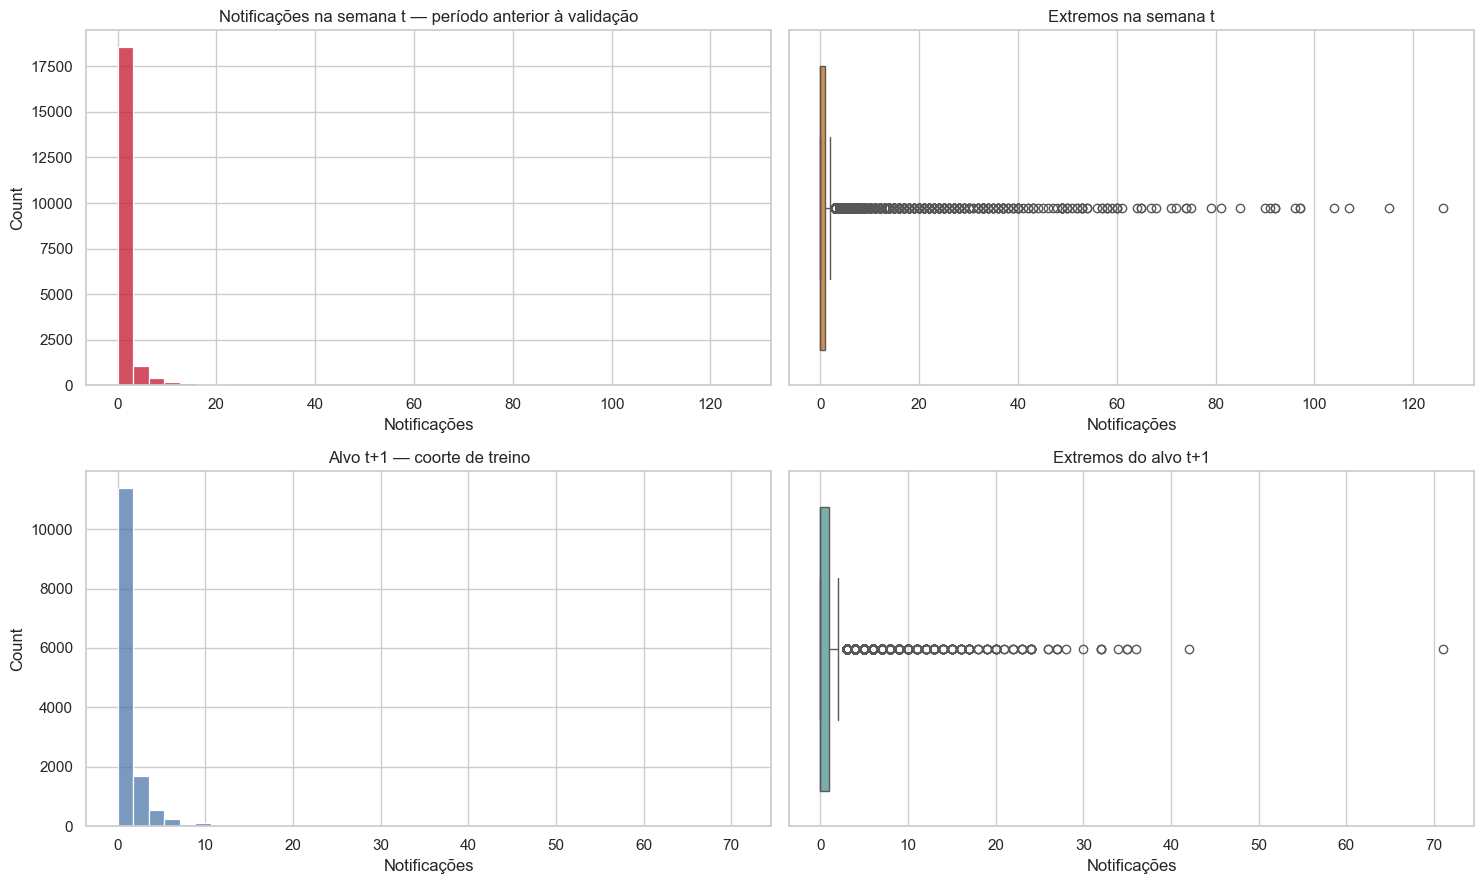

Alvo zero: 60.7%; mediana: 0.0; máximo: 71
Limite IQR: 2.50; pontos para investigação: 1,689
Decisão: preservar picos e usar métricas robustas; extremos podem ser epidemiologicamente reais.


In [17]:
treino_modelo = base_completa.loc[base_completa.CONJUNTO.eq("treino")].copy()
alvo_treino = treino_modelo.NOTIFICACOES_PROXIMA_SEMANA
distribuicao_alvo = pd.DataFrame([{
    "linhas":len(alvo_treino),"zeros":int(alvo_treino.eq(0).sum()),"zeros_pct":100*alvo_treino.eq(0).mean(),
    "media":alvo_treino.mean(),"mediana":alvo_treino.median(),"desvio":alvo_treino.std(),
    "p95":alvo_treino.quantile(.95),"p99":alvo_treino.quantile(.99),"maximo":alvo_treino.max()}])
distribuicao_alvo.to_csv(REPORT_DIR/"distribuicao_alvo_treino.csv",index=False,encoding="utf-8")


# Limiares históricos por bairro para futura tradução da previsão em prioridade operacional.
# São aprendidos somente no treino, não entram como feature e não constituem alerta oficial.
limiares_atencao = treino_modelo.groupby("BAIRRO").NOTIFICACOES_PROXIMA_SEMANA.quantile([.75,.90,.975]).unstack()
limiares_atencao.columns = ["P75_ATENCAO", "P90_ELEVADA", "P975_CRITICA"]
limiares_atencao = limiares_atencao.reset_index()
limiares_atencao.to_csv(REPORT_DIR/"limiares_atencao_treino.csv",index=False,encoding="utf-8")
display(limiares_atencao.head())
print("Bairros com limiares repetidos por excesso de zeros:", int((limiares_atencao.P75_ATENCAO == limiares_atencao.P90_ELEVADA).sum()))
display(distribuicao_alvo)

fig,axes = plt.subplots(2,2,figsize=(15,9))
sns.histplot(base.NOTIFICACOES_SEMANAIS,bins=40,ax=axes[0,0],color="#c5162e")
axes[0,0].set_title("Notificações na semana t — período anterior à validação")
sns.boxplot(x=base.NOTIFICACOES_SEMANAIS,ax=axes[0,1],color="#e58f3c")
axes[0,1].set_title("Extremos na semana t")
sns.histplot(alvo_treino,bins=40,ax=axes[1,0],color="#4c78a8")
axes[1,0].set_title("Alvo t+1 — coorte de treino")
sns.boxplot(x=alvo_treino,ax=axes[1,1],color="#72b7b2")
axes[1,1].set_title("Extremos do alvo t+1")
for ax in axes.flat: ax.set_xlabel("Notificações")
plt.tight_layout();plt.show()

q1,q3 = alvo_treino.quantile([.25,.75]); iqr=q3-q1; limite_superior=q3+1.5*iqr
potenciais_outliers = treino_modelo.loc[alvo_treino.gt(limite_superior)]
print(f"Alvo zero: {alvo_treino.eq(0).mean():.1%}; mediana: {alvo_treino.median():.1f}; máximo: {alvo_treino.max():.0f}")
print(f"Limite IQR: {limite_superior:.2f}; pontos para investigação: {len(potenciais_outliers):,}")
print("Decisão: preservar picos e usar métricas robustas; extremos podem ser epidemiologicamente reais.")

**14.2 Pergunta: em quais anos e meses os registros se concentram?**

Gráfico de barras compara anos; linha mensal evidencia sazonalidade. O resultado ajuda a contar quando a pressão epidemiológica costuma aumentar.

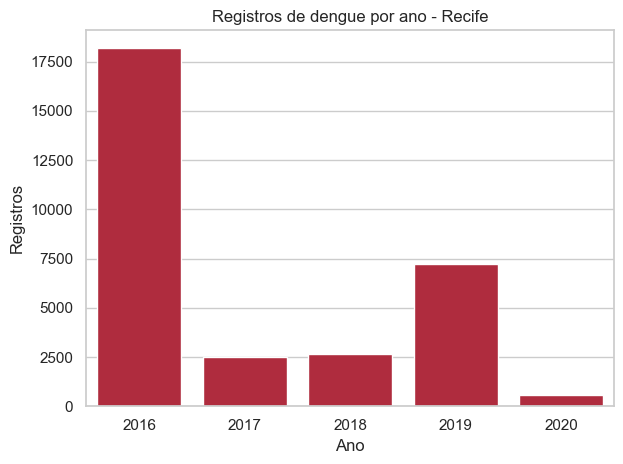

In [18]:
notificacoes_ano = base.groupby("ANO", as_index=False)["NOTIFICACOES_SEMANAIS"].sum()
sns.barplot(data=notificacoes_ano, x="ANO", y="NOTIFICACOES_SEMANAIS", color="#c5162e")
plt.title("Registros de dengue por ano - Recife")
plt.xlabel("Ano")
plt.ylabel("Registros")
plt.tight_layout()
plt.show()

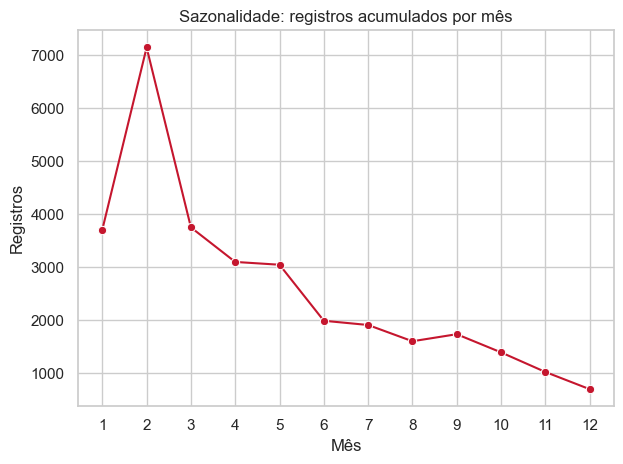

In [19]:
notificacoes_mes = base.groupby("MES", as_index=False)["NOTIFICACOES_SEMANAIS"].sum()
sns.lineplot(data=notificacoes_mes, x="MES", y="NOTIFICACOES_SEMANAIS", marker="o", color="#c5162e")
plt.title("Sazonalidade: registros acumulados por mês")
plt.xticks(range(1, 13))
plt.xlabel("Mês")
plt.ylabel("Registros")
plt.tight_layout()
plt.show()

**14.3 Pergunta: onde está a maior carga territorial?**

O total absoluto indica volume de demanda. A incidência corrige pela população e permite uma comparação mais justa entre bairros de tamanhos diferentes. As duas medidas respondem a perguntas complementares.

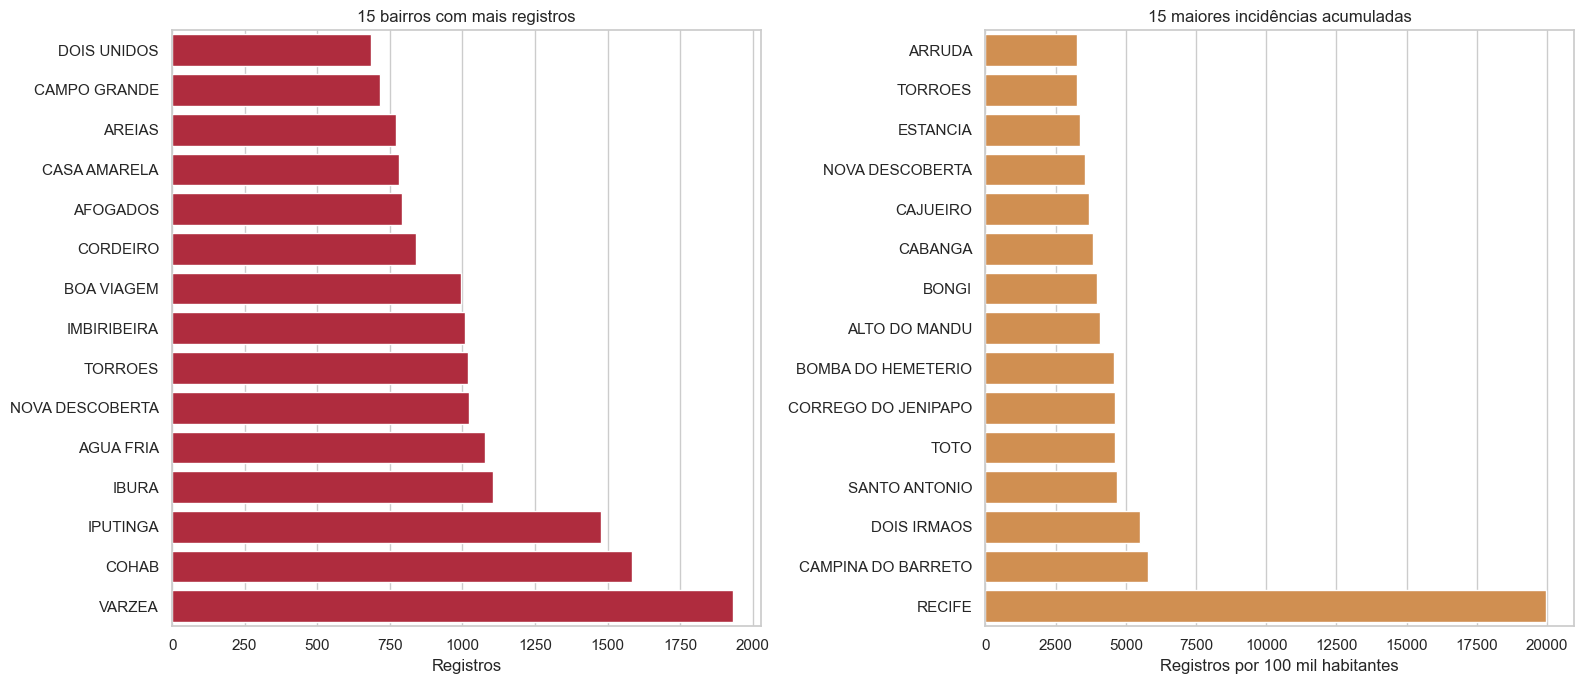

In [20]:
ranking = (
    base.groupby("BAIRRO", as_index=False)
    .agg(
        NOTIFICACOES=("NOTIFICACOES_SEMANAIS", "sum"),
        POPULACAO=("POPULACAO_2022", "first"),
    )
)
ranking["INCIDENCIA_ACUM_100MIL"] = ranking["NOTIFICACOES"] / ranking["POPULACAO"] * 100_000

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

top_notificacoes = ranking.nlargest(15, "NOTIFICACOES").sort_values("NOTIFICACOES")
sns.barplot(data=top_notificacoes, y="BAIRRO", x="NOTIFICACOES", ax=axes[0], color="#c5162e")
axes[0].set_title("15 bairros com mais registros")
axes[0].set_xlabel("Registros")
axes[0].set_ylabel("")

top_inc = ranking.replace([np.inf, -np.inf], np.nan).dropna().nlargest(15, "INCIDENCIA_ACUM_100MIL").sort_values("INCIDENCIA_ACUM_100MIL")
sns.barplot(data=top_inc, y="BAIRRO", x="INCIDENCIA_ACUM_100MIL", ax=axes[1], color="#e58f3c")
axes[1].set_title("15 maiores incidências acumuladas")
axes[1].set_xlabel("Registros por 100 mil habitantes")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**14.4 Pergunta central da AV1: o clima apresenta sinais antecipados em relação aos casos notificados?**

Chuva, temperatura e umidade são avaliadas na escala municipal e por bairro. O clima da semana t é comparado com notificações de t até t+8, cobrindo o intervalo previamente definido a partir do ciclo do vetor, incubação e atraso de notificação. Também são examinadas janelas acumuladas de 2, 4 e 8 semanas.

Pearson mede associação linear; Spearman mede associação monotônica e é menos sensível à forma da distribuição. Nenhuma delas comprova causalidade ou ganho preditivo. Todos os atrasos testados são exportados para evitar relato seletivo.


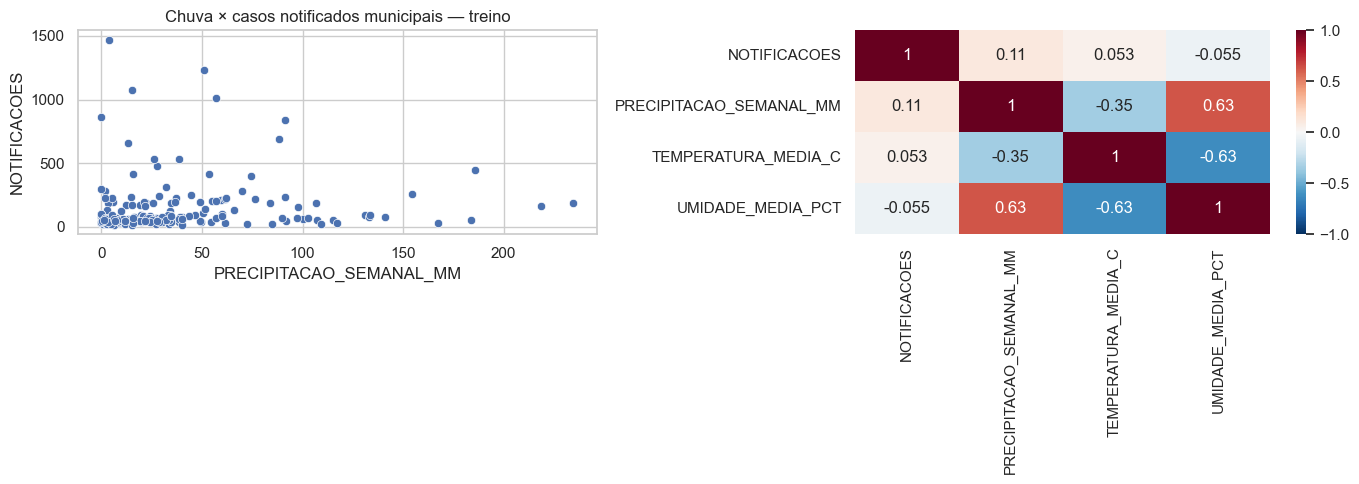

In [21]:
agregacoes_clima = {c:(c,"first") for c in clima_features_modelo}
serie_recife = base.groupby("DATA_SEMANA").agg(
    NOTIFICACOES=("NOTIFICACOES_SEMANAIS", lambda s:s.sum(min_count=len(s))),
    **agregacoes_clima)
# Reindexar inclui semanas sem cobertura como ausentes, nunca zeros.
serie_recife = serie_recife.reindex(pd.date_range(serie_recife.index.min(),serie_recife.index.max(),freq="W-MON"))
fig, axes = plt.subplots(1,2,figsize=(14,5))
sns.scatterplot(data=serie_recife,x="PRECIPITACAO_SEMANAL_MM",y="NOTIFICACOES",ax=axes[0])
colunas_corr = ["NOTIFICACOES","PRECIPITACAO_SEMANAL_MM","TEMPERATURA_MEDIA_C","UMIDADE_MEDIA_PCT"]
sns.heatmap(serie_recife[colunas_corr].corr(),annot=True,vmin=-1,vmax=1,center=0,cmap="RdBu_r",ax=axes[1])
axes[0].set_title("Chuva × casos notificados municipais — treino")
plt.tight_layout(); plt.show()


**Defasagens entre clima e casos notificados**

O atraso zero compara clima e notificações na mesma semana. O atraso k compara o clima observado em t com casos notificados em t+k. As janelas acumuladas terminam em t e são comparadas ao alvo t+1. A faixa 0–8 foi fixada antes de observar os novos resultados.


,variavel_climatica,notificacoes_semanas_depois,pearson,spearman,pares_validos
0,CHUVA,0,0.109176,0.284068,200
1,CHUVA,1,0.121024,0.315096,199
2,CHUVA,2,0.154721,0.360981,198
3,CHUVA,3,0.105482,0.387548,197
4,CHUVA,4,0.130158,0.415868,196
5,CHUVA,5,0.123076,0.372939,195
6,CHUVA,6,0.093960,0.383532,194
7,CHUVA,7,0.108286,0.345190,193
8,CHUVA,8,0.128690,0.339887,192
9,TEMPERATURA,0,0.052963,-0.209115,200


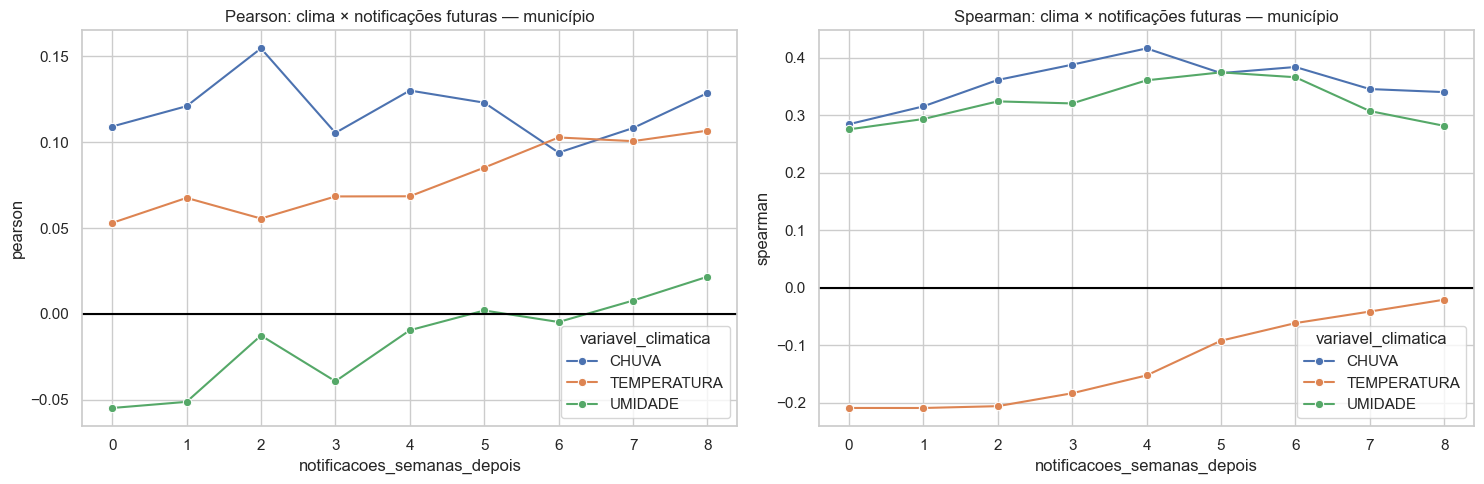

,feature,pearson,spearman,pares_validos
33,CHUVA_8S_MM,0.617750,0.631429,154
35,UMIDADE_MEDIA_8S_PCT,0.337880,0.521598,154
30,CHUVA_4S_MM,0.332802,0.520324,176
27,CHUVA_2S_MM,0.199396,0.421852,190
10,PRECIPITACAO_LAG_8_MM,0.169754,0.381491,191
3,PRECIPITACAO_LAG_1_MM,0.154721,0.360981,198
5,PRECIPITACAO_LAG_3_MM,0.130158,0.415868,196
9,PRECIPITACAO_LAG_7_MM,0.128690,0.339887,192
6,PRECIPITACAO_LAG_4_MM,0.123076,0.372939,195
0,PRECIPITACAO_SEMANAL_MM,0.121024,0.315096,199


,feature,pearson_anomalia_mensal,spearman_anomalia_mensal,pares_validos
2,UMIDADE_MEDIA_PCT,-0.221083,-0.192448,196
33,CHUVA_8S_MM,0.218445,0.196783,154
29,UMIDADE_MEDIA_2S_PCT,-0.197928,-0.212868,187
20,UMIDADE_LAG_2_PCT,-0.179080,-0.179402,194
32,UMIDADE_MEDIA_4S_PCT,-0.176981,-0.156189,173
34,TEMPERATURA_MEDIA_8S_C,0.176631,0.231664,154
19,UMIDADE_LAG_1_PCT,-0.164852,-0.199299,195
30,CHUVA_4S_MM,0.164458,0.137935,176
27,CHUVA_2S_MM,0.136459,0.108225,190
35,UMIDADE_MEDIA_8S_PCT,-0.115256,-0.071781,154


,ANO,pares_validos,pearson,spearman
0,2016,29.0,0.761131,0.865025
1,2017,26.0,-0.065539,0.111929
2,2018,38.0,0.847894,0.759944
3,2019,52.0,0.631486,0.647412
4,2020,9.0,0.086100,0.192470


NOTIFICACOES  PRECIPITACAO_SEMANAL_MM  \
ANO                                                                   
2016 NOTIFICACOES                 1.000000                 0.227120   
     PRECIPITACAO_SEMANAL_MM      0.227120                 1.000000   
     TEMPERATURA_MEDIA_C          0.344463                -0.042156   
     UMIDADE_MEDIA_PCT           -0.434221                 0.291177   
2017 NOTIFICACOES                 1.000000                 0.028641   
     PRECIPITACAO_SEMANAL_MM      0.028641                 1.000000   
     TEMPERATURA_MEDIA_C          0.266165                -0.489737   
     UMIDADE_MEDIA_PCT            0.240717                 0.769481   
2018 NOTIFICACOES                 1.000000                 0.497795   
     PRECIPITACAO_SEMANAL_MM      0.497795                 1.000000   
     TEMPERATURA_MEDIA_C         -0.457955                -0.267585   
     UMIDADE_MEDIA_PCT            0.643572                 0.696632   
2019 NOTIFICACOES                 1.000000                 0.190543   
     PRECIPITACAO_SEMANAL_MM      0.190543                 1.000000   
     TEMPERATURA_MEDIA_C         -0.670442                -0.518150   
     UMIDADE_MEDIA_PCT            0.332817                 0.695094   
2020 NOTIFICACOES                 1.000000                 0.483590   
     PRECIPITACAO_SEMANAL_MM      0.483590                 1.000000   
     TEMPERATURA_MEDIA_C         -0.579649                -0.711709   
     UMIDADE_MEDIA_PCT            0.014989                 0.599233   

                              TEMPERATURA_MEDIA_C  UMIDADE_MEDIA_PCT  
ANO                                                                   
2016 NOTIFICACOES                        0.344463          -0.434221  
     PRECIPITACAO_SEMANAL_MM            -0.042156           0.291177  
     TEMPERATURA_MEDIA_C                 1.000000          -0.820122  
     UMIDADE_MEDIA_PCT                  -0.820122           1.000000  
2017 NOTIFICACOES                        0.266165           0.240717  
     PRECIPITACAO_SEMANAL_MM            -0.489737           0.769481  
     TEMPERATURA_MEDIA_C                 1.000000          -0.501513  
     UMIDADE_MEDIA_PCT                  -0.501513           1.000000  
2018 NOTIFICACOES                       -0.457955           0.643572  
     PRECIPITACAO_SEMANAL_MM            -0.267585           0.696632  
     TEMPERATURA_MEDIA_C                 1.000000          -0.682969  
     UMIDADE_MEDIA_PCT                  -0.682969           1.000000  
2019 NOTIFICACOES                       -0.670442           0.332817  
     PRECIPITACAO_SEMANAL_MM            -0.518150           0.695094  
     TEMPERATURA_MEDIA_C                 1.000000          -0.647879  
     UMIDADE_MEDIA_PCT                  -0.647879           1.000000  
2020 NOTIFICACOES                       -0.579649           0.014989  
     PRECIPITACAO_SEMANAL_MM            -0.711709           0.599233  
     TEMPERATURA_MEDIA_C                 1.000000          -0.399980  
     UMIDADE_MEDIA_PCT                  -0.399980           1.000000

Não há teste causal. Séries autocorrelacionadas e múltiplas janelas exigem validação temporal.


Relações por bairro são exploratórias; muitos testes e autocorrelação impedem tratar o maior r como prova.


r_pearson                               r_spearman  \
                            count    median       min       max      count   
variavel                                                                     
PRECIPITACAO_SEMANAL_MM       837  0.076123 -0.103891  0.329336        837   
TEMPERATURA_MEDIA_C           837  0.054067 -0.312687  0.230345        837   
UMIDADE_MEDIA_PCT             837 -0.012461 -0.167773  0.302537        837   

                                                       
                           median       min       max  
variavel                                               
PRECIPITACAO_SEMANAL_MM  0.166048 -0.141680  0.375338  
TEMPERATURA_MEDIA_C     -0.018797 -0.282134  0.256222  
UMIDADE_MEDIA_PCT        0.085130 -0.180145  0.306039

,NOTIFICACOES,PRECIPITACAO_SEMANAL_MM,TEMPERATURA_MEDIA_C,UMIDADE_MEDIA_PCT
NOTIFICACOES,1.000000,0.038478,-0.085493,-0.242875
PRECIPITACAO_SEMANAL_MM,0.038478,1.000000,-0.369759,0.435109
TEMPERATURA_MEDIA_C,-0.085493,-0.369759,1.000000,-0.417910
UMIDADE_MEDIA_PCT,-0.242875,0.435109,-0.417910,1.000000


In [22]:
linhas = []
for variavel, coluna in {"CHUVA":"PRECIPITACAO_SEMANAL_MM","TEMPERATURA":"TEMPERATURA_MEDIA_C","UMIDADE":"UMIDADE_MEDIA_PCT"}.items():
    for atraso in range(9):
        pares = pd.concat([serie_recife[coluna], serie_recife.NOTIFICACOES.shift(-atraso).rename("FUTURO")],axis=1).dropna()
        linhas.append({"variavel_climatica":variavel,"notificacoes_semanas_depois":atraso,
                       "pearson":pares[coluna].corr(pares.FUTURO,method="pearson"),
                       "spearman":pares[coluna].corr(pares.FUTURO,method="spearman"),"pares_validos":len(pares)})
corr_lags = pd.DataFrame(linhas)
display(corr_lags)
fig,axes=plt.subplots(1,2,figsize=(15,5))
sns.lineplot(data=corr_lags,x="notificacoes_semanas_depois",y="pearson",hue="variavel_climatica",marker="o",ax=axes[0])
sns.lineplot(data=corr_lags,x="notificacoes_semanas_depois",y="spearman",hue="variavel_climatica",marker="o",ax=axes[1])
for ax,titulo in zip(axes,["Pearson","Spearman"]): ax.axhline(0,color="black");ax.set_title(f"{titulo}: clima × notificações futuras — município")
plt.tight_layout();plt.show()
corr_lags.to_csv(REPORT_DIR/"correlacoes_clima_defasagens_treino.csv",index=False,encoding="utf-8")

# Cada atributo climático disponível em t é comparado com o alvo municipal em t+1.
linhas_features = []
for coluna in clima_features_modelo:
    pares = pd.concat([serie_recife[coluna],serie_recife.NOTIFICACOES.shift(-1).rename("ALVO_T1")],axis=1).dropna()
    linhas_features.append({"feature":coluna,"pearson":pares[coluna].corr(pares.ALVO_T1,method="pearson"),
                            "spearman":pares[coluna].corr(pares.ALVO_T1,method="spearman"),"pares_validos":len(pares)})
corr_features_clima = pd.DataFrame(linhas_features)
corr_features_clima.to_csv(REPORT_DIR/"correlacoes_features_climaticas_treino.csv",index=False,encoding="utf-8")
display(corr_features_clima.reindex(corr_features_clima.pearson.abs().sort_values(ascending=False).index).head(12))


# Controle descritivo de sazonalidade: retirar a média de cada mês dentro do treino.
# A associação remanescente é mais conservadora, mas ainda não é causal.
dados_t1 = serie_recife[clima_features_modelo].copy()
dados_t1["ALVO_T1"] = serie_recife.NOTIFICACOES.shift(-1)
anomalias_t1 = dados_t1 - dados_t1.groupby(dados_t1.index.month).transform("mean")
linhas_anomalias = []
for coluna in clima_features_modelo:
    pares = anomalias_t1[[coluna,"ALVO_T1"]].dropna()
    linhas_anomalias.append({"feature":coluna,
        "pearson_anomalia_mensal":pares[coluna].corr(pares.ALVO_T1,method="pearson"),
        "spearman_anomalia_mensal":pares[coluna].corr(pares.ALVO_T1,method="spearman"),
        "pares_validos":len(pares)})
corr_features_anomalias = pd.DataFrame(linhas_anomalias)
corr_features_anomalias.to_csv(REPORT_DIR/"correlacoes_features_climaticas_anomalias_treino.csv",index=False,encoding="utf-8")
display(corr_features_anomalias.reindex(corr_features_anomalias.pearson_anomalia_mensal.abs().sort_values(ascending=False).index).head(12))

# Estabilidade anual da principal janela acumulada, sem combinar anos favoráveis seletivamente.
chuva8_t1 = pd.concat([serie_recife.CHUVA_8S_MM,serie_recife.NOTIFICACOES.shift(-1).rename("ALVO_T1")],axis=1).dropna()
chuva8_por_ano = chuva8_t1.assign(ANO=chuva8_t1.index.year).groupby("ANO").apply(
    lambda g: pd.Series({"pares_validos":len(g),
        "pearson":g.CHUVA_8S_MM.corr(g.ALVO_T1,method="pearson"),
        "spearman":g.CHUVA_8S_MM.corr(g.ALVO_T1,method="spearman")}),
    include_groups=False).reset_index()
chuva8_por_ano.to_csv(REPORT_DIR/"correlacao_chuva8_por_ano_treino.csv",index=False,encoding="utf-8")
display(chuva8_por_ano)

# Verificar estabilidade entre anos: correlação agregada pode refletir sazonalidade comum.
colunas_anuais = ["NOTIFICACOES","PRECIPITACAO_SEMANAL_MM","TEMPERATURA_MEDIA_C","UMIDADE_MEDIA_PCT"]
por_ano = serie_recife.assign(ANO=serie_recife.index.year).groupby("ANO")[colunas_anuais].corr()
display(por_ano)
print("Não há teste causal. Séries autocorrelacionadas e múltiplas janelas exigem validação temporal.")

linhas_bairro = []
for bairro,g in base.groupby("BAIRRO"):
    g = g.set_index("DATA_SEMANA").reindex(serie_recife.index)
    for clima in clima_atual:
        for lag in range(9):
            pares = pd.concat([g[clima],g.NOTIFICACOES_SEMANAIS.shift(-lag).rename("FUTURO")],axis=1).dropna()
            valido_corr = len(pares)>=30 and pares[clima].nunique()>1 and pares.FUTURO.nunique()>1
            linhas_bairro.append({"BAIRRO":bairro,"variavel":clima,"defasagem":lag,"n_pares":len(pares),
                                  "r_pearson":pares[clima].corr(pares.FUTURO,method="pearson") if valido_corr else np.nan,
                                  "r_spearman":pares[clima].corr(pares.FUTURO,method="spearman") if valido_corr else np.nan})
corr_bairros = pd.DataFrame(linhas_bairro)
corr_bairros.to_csv(REPORT_DIR/"correlacoes_por_bairro_treino.csv",index=False,encoding="utf-8")
print("Relações por bairro são exploratórias; muitos testes e autocorrelação impedem tratar o maior r como prova.")
display(corr_bairros.groupby("variavel")[["r_pearson","r_spearman"]].agg(["count","median","min","max"]))

# Remover médias mensais diagnostica sazonalidade comum; não identifica causalidade.
dessazonalizada = serie_recife[colunas_anuais] - serie_recife[colunas_anuais].groupby(serie_recife.index.month).transform("mean")
display(dessazonalizada.corr())
dessazonalizada.corr().to_csv(REPORT_DIR/"correlacao_apos_media_mensal_treino.csv")


**14.6 EDA específica das novas features climáticas e históricas**

**Objetivo:** verificar ausências geradas pelas janelas completas, distribuições, redundâncias e relações com o alvo apenas no treino. Correlação fraca isolada não elimina utilidade não linear; correlação alta isolada também não prova generalização.

As perdas por construção das features são quantificadas na tabela da coorte. Todos os atrasos climáticos de 1–8 e janelas de 2/4/8 são preservados para o protocolo da AV2. A utilidade preditiva será medida por validação temporal, mantendo o teste reservado.


,ausentes_pct,mediana,min,max
NOTIFICACOES_LAG_1,0.456621,0.000000,0.000000,126.000000
NOTIFICACOES_LAG_2,0.913242,0.000000,0.000000,126.000000
NOTIFICACOES_LAG_3,1.369863,0.000000,0.000000,126.000000
NOTIFICACOES_LAG_4,1.826484,0.000000,0.000000,126.000000
MEDIA_NOTIFICACOES_4S,1.826484,0.500000,0.000000,93.000000
PRECIPITACAO_LAG_1_MM,9.132420,20.800000,0.000000,234.600000
PRECIPITACAO_LAG_2_MM,9.589041,20.800000,0.000000,234.600000
PRECIPITACAO_LAG_3_MM,10.045662,20.800000,0.000000,234.600000
PRECIPITACAO_LAG_4_MM,10.502283,20.600000,0.000000,234.600000
PRECIPITACAO_LAG_5_MM,10.958904,20.800000,0.000000,234.600000


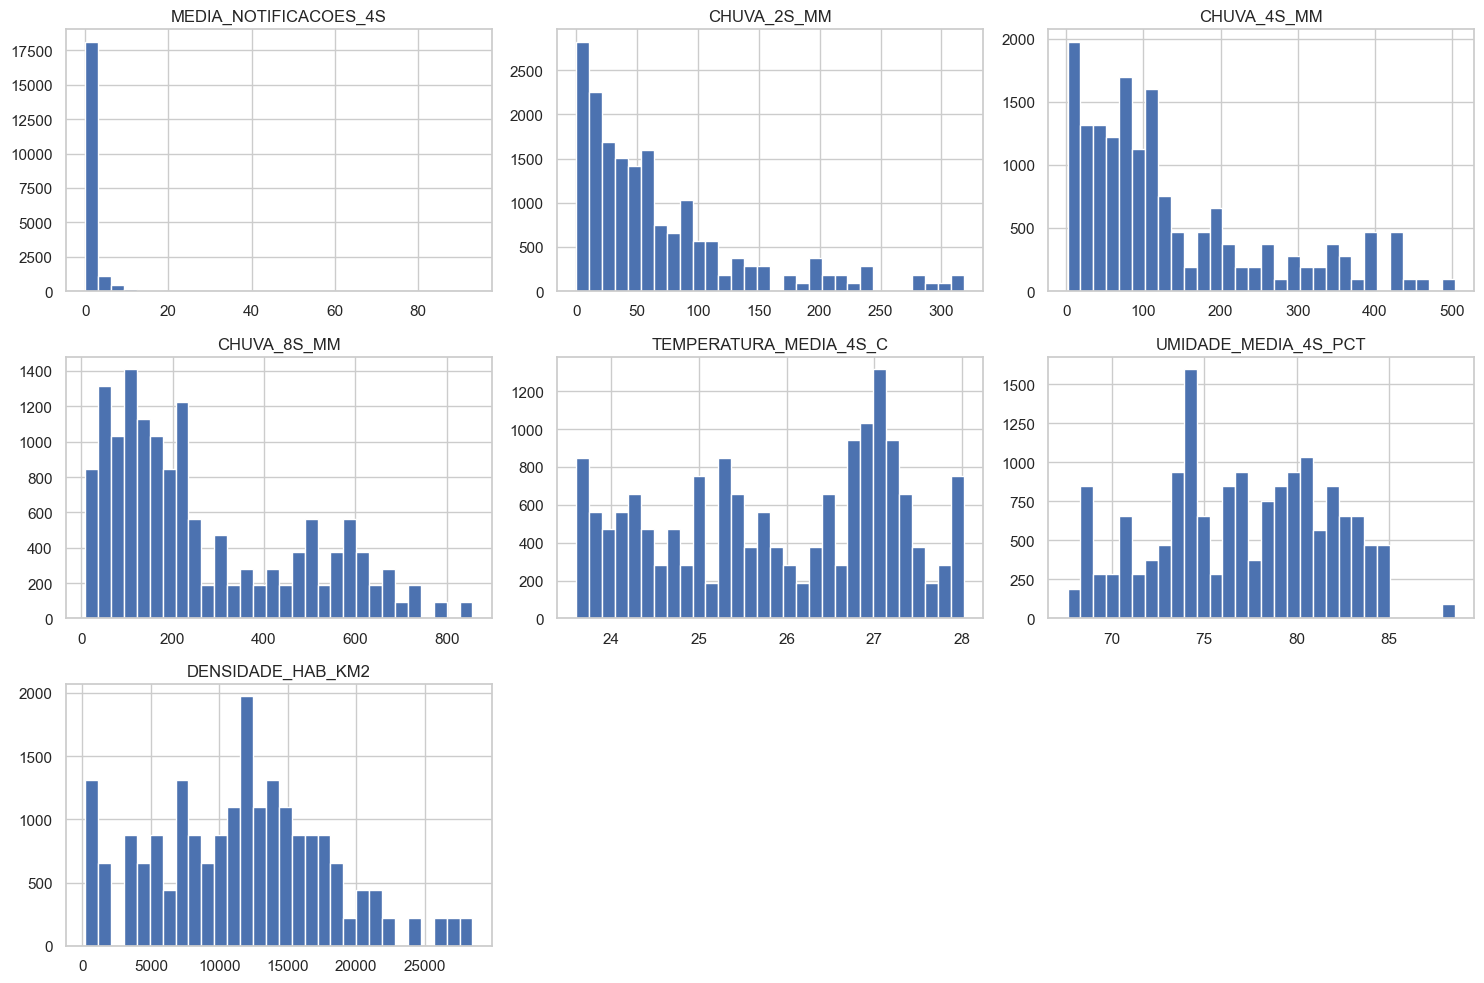

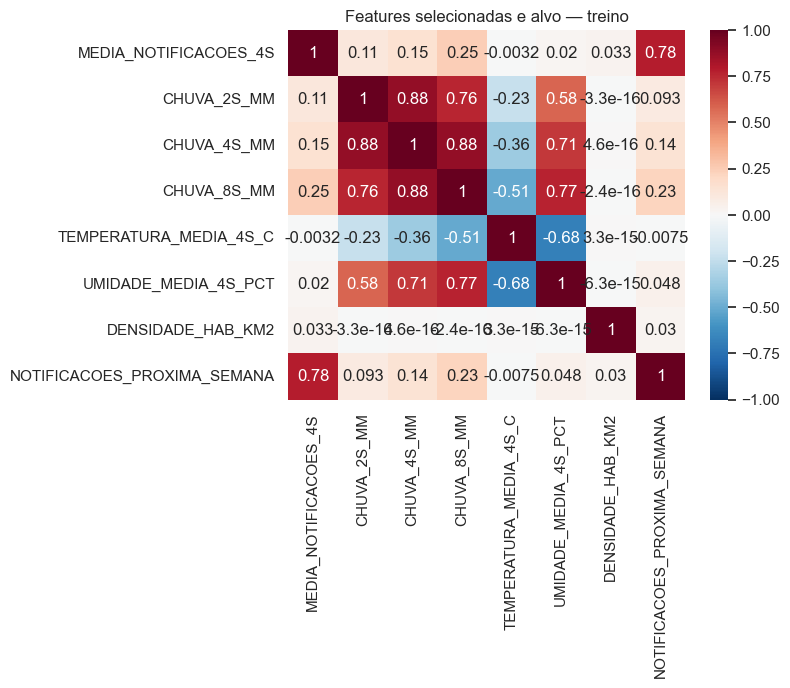

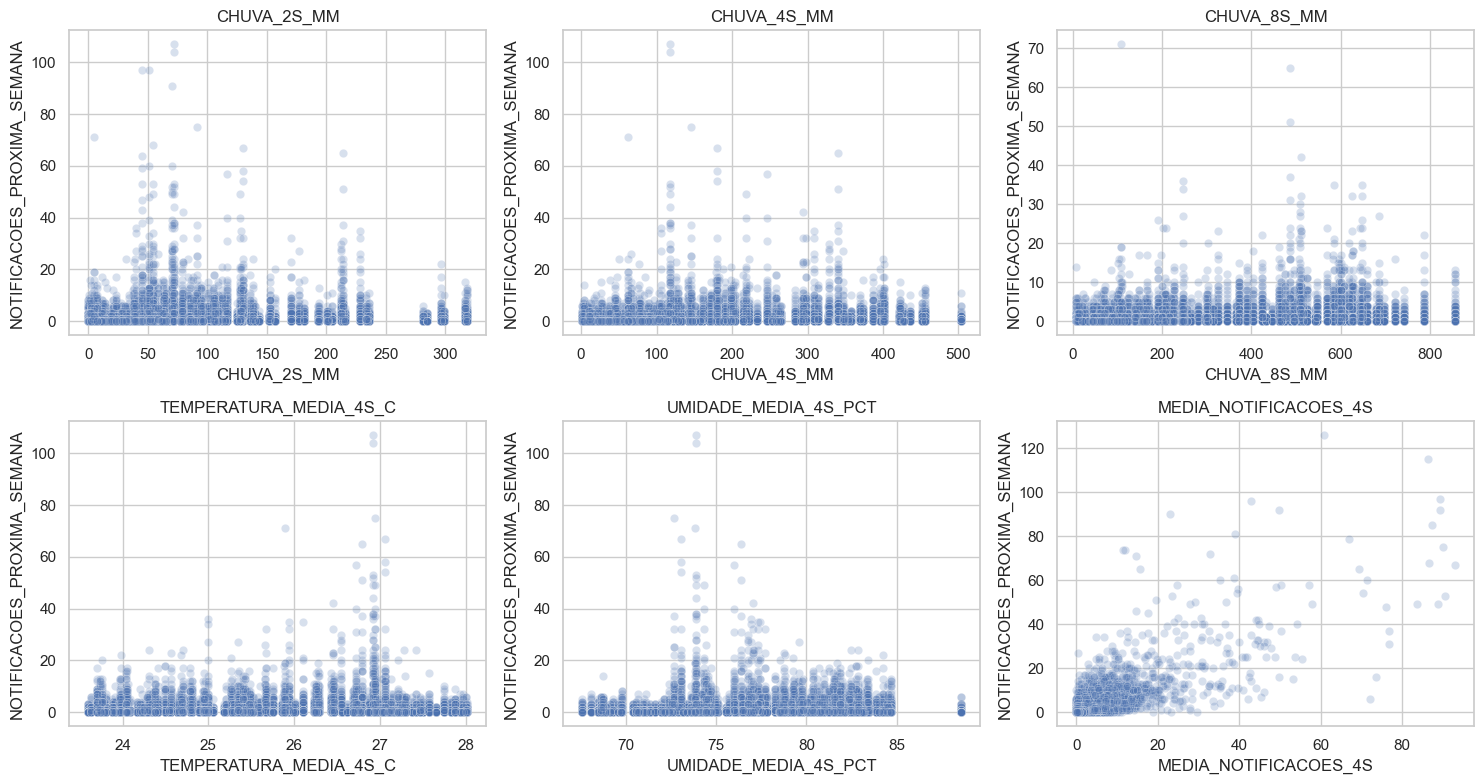

In [23]:
resumo_features = pd.DataFrame({"ausentes_pct":base[features_criadas].isna().mean()*100,
    "mediana":base[features_criadas].median(),"min":base[features_criadas].min(),"max":base[features_criadas].max()})
display(resumo_features)
resumo_features.to_csv(REPORT_DIR/"eda_features_treino.csv")

features_grafico = ["MEDIA_NOTIFICACOES_4S","CHUVA_2S_MM","CHUVA_4S_MM","CHUVA_8S_MM",
                    "TEMPERATURA_MEDIA_4S_C","UMIDADE_MEDIA_4S_PCT","DENSIDADE_HAB_KM2"]
base[features_grafico].hist(figsize=(15,10),bins=30);plt.tight_layout();plt.show()
sns.heatmap(base[features_grafico + ["NOTIFICACOES_PROXIMA_SEMANA"]].corr(),cmap="RdBu_r",center=0,vmin=-1,vmax=1,annot=True)
plt.title("Features selecionadas e alvo — treino");plt.show()
fig,axes = plt.subplots(2,3,figsize=(15,8))
for ax,c in zip(axes.flat,["CHUVA_2S_MM","CHUVA_4S_MM","CHUVA_8S_MM","TEMPERATURA_MEDIA_4S_C","UMIDADE_MEDIA_4S_PCT","MEDIA_NOTIFICACOES_4S"]):
    sns.scatterplot(data=base,x=c,y="NOTIFICACOES_PROXIMA_SEMANA",alpha=.22,ax=ax)
    ax.set_title(c)
plt.tight_layout();plt.show()


## 15. Normalização, padronização e preparação para AV2
**Min-Max:** `(x − mínimo do treino)/(máximo − mínimo do treino)`. Em geral deixa o treino entre 0 e 1, mas valores futuros podem sair dessa faixa. Sensível a extremos.  
**StandardScaler:** `(x − média do treino)/desvio padrão do treino`. Centraliza e ajusta escala; não torna a distribuição normal e não elimina assimetria ou outliers.

Aplicamos e comparamos as duas alternativas às **entradas numéricas**, em pipelines separados. Não aplicamos uma após a outra. Não escalonamos alvo, datas, identificadores ou códigos de categoria. Imputação por mediana e codificação de categorias são aprendidas apenas no treino.

Os atributos climáticos de 1–8 semanas e janelas de 2/4/8 são candidatos definidos pela hipótese, não vencedores antecipados. Na AV2, seleção, regularização e importância serão aprendidas dentro dos folds temporais. Para Poisson, a padronização coloca entradas em escalas comparáveis; árvores e Random Forest serão avaliadas sem escala. Incidência, mês, trimestre e período chuvoso permanecem descritivos no conjunto inicial para reduzir redundância.


,original,padronizado_media,padronizado_min,padronizado_max,normalizado_media,normalizado_min,normalizado_max,original_desvio,padronizado_desvio,normalizado_desvio
NOTIFICACOES_SEMANAIS,1.080386,-4.510647e-15,-0.414959,26.854983,0.015217,0.0,1.0,2.603599,1.0,0.036670
NOTIFICACOES_LAG_1,1.109201,4.846529e-16,-0.410287,25.852214,0.015623,0.0,1.0,2.703474,1.0,0.038077
NOTIFICACOES_LAG_2,1.138791,-2.515414e-15,-0.407485,24.997918,0.016039,0.0,1.0,2.794681,1.0,0.039362
NOTIFICACOES_LAG_3,1.184937,1.564911e-15,-0.397203,23.402716,0.016689,0.0,1.0,2.983203,1.0,0.042017
NOTIFICACOES_LAG_4,1.212414,1.441999e-15,-0.390235,23.749729,0.016166,0.0,1.0,3.106881,1.0,0.041425
MEDIA_NOTIFICACOES_4S,1.161336,5.732189e-16,-0.470500,22.014608,0.020925,0.0,1.0,2.468300,1.0,0.044474
PRECIPITACAO_SEMANAL_MM,28.998675,8.752303e-15,-0.795397,5.639382,0.123609,0.0,1.0,36.458133,1.0,0.155406
TEMPERATURA_MEDIA_C,25.904394,3.558832e-13,-1.973018,1.871860,0.513155,0.0,1.0,1.363750,1.0,0.260086
UMIDADE_MEDIA_PCT,76.510865,-2.242679e-13,-2.055259,2.365952,0.464863,0.0,1.0,4.918927,1.0,0.226182
PRECIPITACAO_LAG_1_MM,30.282119,1.072866e-14,-0.776591,5.239774,0.129080,0.0,1.0,38.993640,1.0,0.166213


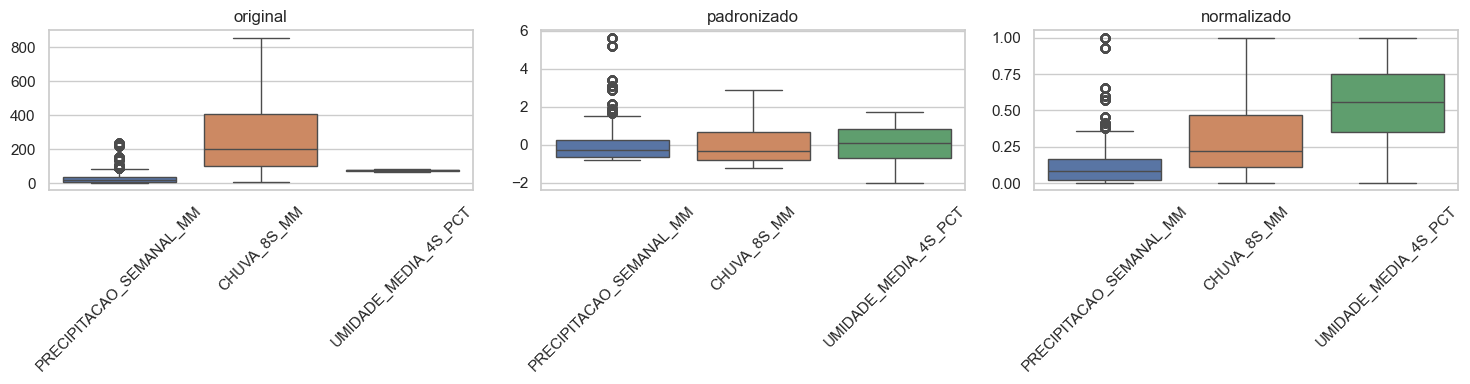

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
import joblib

numericas = (["NOTIFICACOES_SEMANAIS"] + features_historicas + clima_features_modelo +
             ["POPULACAO_2022", "DENSIDADE_HAB_KM2", "SEMANA_SIN", "SEMANA_COS"])
categoricas = ["BAIRRO", "RPA"]
entradas = numericas + categoricas
X_treino = base_completa.loc[base_completa.CONJUNTO.eq("treino"), entradas].copy()
X_treino[categoricas] = X_treino[categoricas].fillna("AUSENTE").astype(str)
if X_treino[numericas].notna().sum().eq(0).any():
    raise ValueError("Há entrada numérica totalmente ausente no treino; rever fonte/cobertura antes de imputar.")
preprocessadores = {}
for nome, escalador in [("padronizado", StandardScaler()), ("normalizado", MinMaxScaler()), ("sem_escala", "passthrough")]:
    prep = ColumnTransformer([
        ("numericas", Pipeline([("imputacao", SimpleImputer(strategy="median",add_indicator=True)), ("escala", escalador)]), numericas),
        ("categoricas", OneHotEncoder(handle_unknown="ignore",sparse_output=False), categoricas)], remainder="drop")
    prep.fit(X_treino)
    preprocessadores[nome] = prep
    joblib.dump(prep, DATA_DIR/f"preprocessador_{nome}.joblib")

comparacao = pd.DataFrame({"original":X_treino[numericas].mean()})
for nome in ["padronizado", "normalizado"]:
    valores = preprocessadores[nome].transform(X_treino)[:, :len(numericas)]
    comparacao[nome + "_media"] = valores.mean(axis=0)
    comparacao[nome + "_min"] = valores.min(axis=0)
    comparacao[nome + "_max"] = valores.max(axis=0)
comparacao["original_desvio"] = X_treino[numericas].std(ddof=0)
for nome in ["padronizado","normalizado"]:
    comparacao[nome+"_desvio"] = preprocessadores[nome].transform(X_treino)[:,:len(numericas)].std(axis=0)
display(comparacao)
comparacao.to_csv(REPORT_DIR/"comparacao_escalas_treino.csv")

config = {"entradas_numericas":numericas,"entradas_categoricas":categoricas,"alvo":"NOTIFICACOES_PROXIMA_SEMANA",
 "corte_validacao":str(corte1.date()),"corte_teste":str(corte2.date()),
 "intervalos_cobertura":INTERVALOS_COBERTURA_CONFIRMADA,"justificativa_cobertura":JUSTIFICATIVA_COBERTURA,"cobertura_minima_clima":COBERTURA_MINIMA_CLIMA,
 "definicao_alvo":"Quantidade de casos notificados A90 para o mesmo bairro em t+1; não equivale a casos confirmados.",
 "hipotese_principal":"Chuva, temperatura e umidade, com atrasos de 1–8 semanas e janelas 2/4/8, acrescentam capacidade preditiva.",
 "coorte_principal":"Mesmas linhas com histórico e todas as features climáticas completas para comparação justa com e sem clima.",
 "nota":"Preprocessadores AV1 ajustados apenas no treino. Recriar dentro de cada fold temporal da AV2."}
(DATA_DIR/"config_av2.json").write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding="utf-8")

fig,axes = plt.subplots(1,3,figsize=(15,4))
medidas_exemplo=["PRECIPITACAO_SEMANAL_MM","CHUVA_8S_MM","UMIDADE_MEDIA_4S_PCT"]
for ax,nome in zip(axes,["original","padronizado","normalizado"]):
    valores = X_treino[numericas] if nome=="original" else pd.DataFrame(preprocessadores[nome].transform(X_treino)[:,:len(numericas)],columns=numericas)
    sns.boxplot(data=valores[medidas_exemplo],ax=ax)
    ax.set_title(nome);ax.tick_params(axis="x",rotation=45)
plt.tight_layout();plt.show()


## 16. Principais descobertas

Esta célula transforma os resultados em uma narrativa automática, evitando encerrar a EDA apenas com gráficos.

In [25]:
print("RESUMO REAL — SOMENTE DADOS ANTERIORES À VALIDAÇÃO QUANDO APLICÁVEL")
print("Linhas lidas:",len(dengue),"| Registros válidos:",len(df_limpo),"| Bairros:",base.BAIRRO.nunique())
print("Período da EDA:",base.DATA_SEMANA.min().date(),"a",base.DATA_SEMANA.max().date())
print("Foco: clima e seus efeitos defasados; alvo operacional: casos notificados A90 em t+1.")
print("Coorte comum:",int(base_completa.ELEGIVEL_AV2.sum()),"de",len(base_completa),f"({base_completa.ELEGIVEL_AV2.mean():.1%})")
print("Distribuição do alvo no treino:")
display(distribuicao_alvo)
print("Maior volume por ano na EDA:",notificacoes_ano.loc[notificacoes_ano.NOTIFICACOES_SEMANAIS.idxmax()].to_dict())
print("Maior volume por bairro na EDA:",ranking.loc[ranking.NOTIFICACOES.idxmax(),["BAIRRO","NOTIFICACOES"]].to_dict())
melhor_pearson = corr_lags.loc[corr_lags.pearson.abs().idxmax()]
melhor_spearman = corr_lags.loc[corr_lags.spearman.abs().idxmax()]
melhor_feature = corr_features_clima.loc[corr_features_clima.pearson.abs().idxmax()]
melhor_anomalia = corr_features_anomalias.loc[corr_features_anomalias.pearson_anomalia_mensal.abs().idxmax()]
print("Maior Pearson entre clima semanal e notificações futuras:");display(melhor_pearson.to_frame("resultado"))
print("Maior Spearman entre clima semanal e notificações futuras:");display(melhor_spearman.to_frame("resultado"))
print("Maior Pearson entre feature climática em t e alvo t+1:");display(melhor_feature.to_frame("resultado"))
print("Maior Pearson após retirar médias mensais do treino:");display(melhor_anomalia.to_frame("resultado"))
print("Associação exploratória não demonstra causalidade nem ganho preditivo; validação e teste estão reservados.")
summary = {
 "linhas_lidas":len(dengue),"registros_validos":len(df_limpo),"notificacoes_treino_eda":int(base.NOTIFICACOES_SEMANAIS.sum()),
 "inicio_eda":str(base.DATA_SEMANA.min().date()),"fim_eda":str(base.DATA_SEMANA.max().date()),
 "corte_validacao":str(corte1.date()),"corte_teste":str(corte2.date()),
 "coorte_comum":int(base_completa.ELEGIVEL_AV2.sum()),"retencao_coorte_pct":100*base_completa.ELEGIVEL_AV2.mean(),
 "distribuicao_alvo_treino":distribuicao_alvo.iloc[0].to_dict(),
 "melhor_pearson_lag":melhor_pearson.to_dict(),"melhor_spearman_lag":melhor_spearman.to_dict(),
 "melhor_feature_climatica_pearson":melhor_feature.to_dict(),"melhor_feature_anomalia_mensal":melhor_anomalia.to_dict(),
 "correlacoes_lags":corr_lags.to_dict("records"),"correlacoes_features_climaticas":corr_features_clima.to_dict("records"),
 "qualidade_por_ano":qualidade_ano.reset_index().to_dict("records"),
 "conjuntos":base_completa.groupby("CONJUNTO").size().to_dict(),"ids_ano_divergentes":int(conflitos.sum())}
(REPORT_DIR/"resumo_execucao_real.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding="utf-8")


RESUMO REAL — SOMENTE DADOS ANTERIORES À VALIDAÇÃO QUANDO APLICÁVEL
Linhas lidas: 71663 | Registros válidos: 71175 | Bairros: 94
Período da EDA: 2016-01-04 a 2020-03-09
Foco: clima e seus efeitos defasados; alvo operacional: casos notificados A90 em t+1.
Coorte comum: 20304 de 49162 (41.3%)
Distribuição do alvo no treino:


,linhas,zeros,zeros_pct,media,mediana,desvio,p95,p99,maximo
0,14194,8621,60.736931,1.047837,0.0,2.437213,5.0,11.0,71.0


Maior volume por ano na EDA: {'ANO': 2016.0, 'NOTIFICACOES_SEMANAIS': 18185.0}
Maior volume por bairro na EDA: {'BAIRRO': 'VARZEA', 'NOTIFICACOES': 1931.0}
Maior Pearson entre clima semanal e notificações futuras:


,resultado
variavel_climatica,CHUVA
notificacoes_semanas_depois,2
pearson,0.154721
spearman,0.360981
pares_validos,198


Maior Spearman entre clima semanal e notificações futuras:


,resultado
variavel_climatica,CHUVA
notificacoes_semanas_depois,4
pearson,0.130158
spearman,0.415868
pares_validos,196


... (2 outputs left out)

Maior Pearson após retirar médias mensais do treino:


,resultado
feature,UMIDADE_MEDIA_PCT
pearson_anomalia_mensal,-0.221083
spearman_anomalia_mensal,-0.192448
pares_validos,196


Associação exploratória não demonstra causalidade nem ganho preditivo; validação e teste estão reservados.


14535

**Decisões consolidadas e limitações para a AV2**

- O foco da hipótese é o clima; o alvo operacional é a quantidade de casos notificados A90, não casos necessariamente confirmados.
- O histórico de notificações é apoio temporal e controle comparativo, não substituto da hipótese climática.
- Atrasos climáticos de 1–8 semanas e janelas 2/4/8 foram fixados por plausibilidade biológica antes dos novos resultados.
- Todos os atrasos testados são exportados; não se escolhe apenas o maior coeficiente para afirmar relação.
- Atrasos e revisões retrospectivas podem fazer o dado histórico diferir do que estaria disponível em tempo real.
- Zeros significam ausência de registro na fonte sob a hipótese documentada de cobertura, não ausência real de infecção.
- Registros fora do ano nominal são mantidos pela data real; cópias exatas globais são removidas.
- IDs-ano divergentes são preservados no cenário principal e comparados com um cenário conservador agregado.
- População fixa de 2022 e uma única estação climática limitam inferências históricas e hiperlocais.
- A301 possui série válida para a coorte comum até 2021; 2022 e 2023 têm linhas horárias sem as três medições. O protótipo posterior continua ilustrativo.
- Correlações Pearson e Spearman não comprovam causalidade nem desempenho preditivo; a resposta final exige comparação temporal com e sem clima na AV2.
- Limiares históricos de prioridade são preparados no treino e não constituem alertas epidemiológicos oficiais.

**Critério para iniciar a AV2:** execução integral sem erro, artefatos UTF-8, perdas reconciliadas, atributos climáticos completos, alvo e coorte fixados, teste temporal preservado e limitações incorporadas ao protocolo experimental.


## 17. Exportação da base revisada

In [26]:
base_final = base_completa.copy()
assert not base_final.duplicated(["BAIRRO", "DATA_SEMANA"]).any()
assert base_final.loc[~base_final.COBERTURA_DENGUE, "NOTIFICACOES_SEMANAIS"].isna().all()
assert base_final.loc[base_final.CONJUNTO.isin(["treino","validacao","teste"]), "NOTIFICACOES_PROXIMA_SEMANA"].notna().all()
caminho_saida = DATA_DIR / "dataset_av1_revisado.csv"
base_final.to_csv(caminho_saida,index=False,encoding="utf-8-sig")
colunas = pd.DataFrame({"variavel":base_final.columns,"dtype":base_final.dtypes.astype(str).values,
                        "ausentes":base_final.isna().sum().values,"percentual_ausente":base_final.isna().mean().values*100})
colunas.to_csv(REPORT_DIR/"dicionario_tipos_ausencias.csv",index=False)
print("Base exportada:", caminho_saida, base_final.shape)
print("Escala original preservada; pipelines de escala são separados e ajustados só no treino.")
import importlib.metadata as metadata
versoes = {nome:metadata.version(nome) for nome in ["pandas","numpy","matplotlib","seaborn","scikit-learn","openpyxl","joblib"]}
manifesto = {"inicio_utc":RUN_INICIO,"fim_utc":datetime.now(timezone.utc).isoformat(),"python":platform.python_version(),
 "versoes":versoes,"fontes":EXECUCAO_FONTES,"cobertura":INTERVALOS_COBERTURA_CONFIRMADA,
 "justificativa_cobertura":JUSTIFICATIVA_COBERTURA,"linhas_painel":len(base_final),
 "colunas":len(base_final.columns),"definicao_alvo":"notificações A90 publicadas por bairro na semana t+1",
 "coorte_elegivel":int(base_final.ELEGIVEL_AV2.sum()),
 "status":"executado_com_fontes_oficiais_pronto_para_av2_com_limitacoes_documentadas"}
(DATA_DIR/"manifesto_execucao.json").write_text(json.dumps(manifesto,ensure_ascii=False,indent=2),encoding="utf-8")
print("Execução técnica concluída. Confirmar origem das entradas e interpretar resultados antes de declarar AV1 encerrada.")
# Acrescentar significado, papel e unidade ao dicionário automático.
descricoes = {
 "BAIRRO":("Bairro de residência padronizado","categoria","Recife/IBGE"),
 "RPA":("Região Político-Administrativa","categoria","Prefeitura"),
 "DATA_SEMANA":("Segunda-feira da semana civil local","data","derivada da notificação"),
 "ANO":("Ano ISO da semana civil, não ano do arquivo","ano","calendário"),
 "SEMANA":("Número ISO da semana civil","semana","calendário"),
 "COBERTURA_DENGUE":("Sete dias dentro da hipótese operacional de cobertura da fonte anual","booleano","configuração"),
 "REGISTROS_OBSERVADOS":("Notificações encontradas antes de validar cobertura semanal","registros","Recife"),
 "NOTIFICACOES_SEMANAIS":("Notificações na semana t; nome legado não implica confirmação","registros","Recife"),
 "POPULACAO_2022":("População fixa de referência","habitantes","IBGE 2022"),
 "AREA_KM2_IBGE":("Área territorial do bairro","km²","IBGE 2022"),
 "DENSIDADE_HAB_KM2":("População dividida pela área","habitantes/km²","derivada"),
 "INCIDENCIA_100MIL":("Notificações/população multiplicado por 100.000","registros/100 mil hab.","derivada"),
 "PRECIPITACAO_SEMANAL_MM":("Soma observada da precipitação na semana t","mm","INMET A301"),
 "TEMPERATURA_MEDIA_C":("Média horária das temperaturas válidas na semana t","°C","INMET A301"),
 "UMIDADE_MEDIA_PCT":("Média horária da umidade válida na semana t","%","INMET A301"),
 "CHUVA_4S_MM":("Soma das quatro semanas t−3 a t, todas válidas","mm","derivada do INMET"),
 "MEDIA_NOTIFICACOES_4S":("Média das quatro semanas t−4 a t−1, todas válidas","registros/semana","derivada"),
 "MES":("Mês da segunda-feira de referência","mês","calendário"),
 "TRIMESTRE":("Trimestre da segunda-feira de referência","trimestre","calendário"),
 "PERIODO_CHUVOSO":("Indicador descritivo março–agosto; regra a justificar","0/1","regra herdada"),
 "SEMANA_SIN":("Seno do ciclo anual pelo dia do ano","adimensional","calendário"),
 "SEMANA_COS":("Cosseno do ciclo anual pelo dia do ano","adimensional","calendário"),
 "NOTIFICACOES_PROXIMA_SEMANA":("Notificações na semana t+1 do mesmo bairro","registros","alvo derivado"),
 "DATA_ALVO":("Segunda-feira da semana prevista t+1","data","calendário"),
 "ELEGIVEL_SEM_CLIMA":("Alvo e histórico disponíveis, independentemente do clima","booleano","controle"),
 "ELEGIVEL_AV2":("Alvo, histórico e clima disponíveis na coorte comum","booleano","controle"),
 "CONJUNTO":("Treino, validação, teste ou fora da coorte","categoria","controle temporal"),
}
for k in range(1,5): descricoes[f"NOTIFICACOES_LAG_{k}"]=(f"Notificações do bairro em t−{k}","registros","derivada")

for atraso in range(1,9):
    descricoes[f"PRECIPITACAO_LAG_{atraso}_MM"]=(f"Precipitação semanal em t−{atraso}","mm","derivada do INMET")
    descricoes[f"TEMPERATURA_LAG_{atraso}_C"]=(f"Temperatura média semanal em t−{atraso}","°C","derivada do INMET")
    descricoes[f"UMIDADE_LAG_{atraso}_PCT"]=(f"Umidade média semanal em t−{atraso}","%","derivada do INMET")
for janela in [2,4,8]:
    descricoes[f"CHUVA_{janela}S_MM"]=(f"Chuva acumulada nas {janela} semanas terminando em t","mm","derivada do INMET")
    descricoes[f"TEMPERATURA_MEDIA_{janela}S_C"]=(f"Temperatura média das {janela} semanas terminando em t","°C","derivada do INMET")
    descricoes[f"UMIDADE_MEDIA_{janela}S_PCT"]=(f"Umidade média das {janela} semanas terminando em t","%","derivada do INMET")
for variavel in ["CHUVA","TEMPERATURA","UMIDADE"]:
    descricoes[f"HORAS_{variavel}"]=(f"Horas válidas de {variavel.lower()} na semana","horas","INMET A301")
    descricoes[f"COBERTURA_{variavel}"]=(f"Horas válidas de {variavel.lower()} divididas por 168","fração 0–1","derivada do INMET")
assert set(base_final.columns).issubset(descricoes), "Completar o dicionário para novas colunas."
dic = colunas.copy()
for j,campo in enumerate(["descricao","unidade","origem"]): dic[campo]=dic.variavel.map(lambda x:descricoes[x][j])
dic["papel"] = dic.variavel.map(lambda x:"alvo" if x=="NOTIFICACOES_PROXIMA_SEMANA" else "entrada candidata" if x in entradas else "controle/descritiva")
dic["tipo_conceitual"] = dic.variavel.map(lambda x:"categórica nominal" if x in ["BAIRRO","RPA","CONJUNTO"] else "data" if x in ["DATA_SEMANA","DATA_ALVO"] else "binária" if x.startswith("ELEGIVEL") or x in ["COBERTURA_DENGUE","PERIODO_CHUVOSO"] else "numérica")
dic.to_csv(REPORT_DIR/"dicionario_completo.csv",index=False)


Base exportada: C:\Users\beloa\OneDrive\Documentos\ChatGPT\Machine Larning AV2\tmp\av1_reexec_clima_20261117\dados_av1_revisada\dataset_av1_revisado.csv (49162, 69)
Escala original preservada; pipelines de escala são separados e ajustados só no treino.
Execução técnica concluída. Confirmar origem das entradas e interpretar resultados antes de declarar AV1 encerrada.


**17.1 Download opcional**

No Colab, execute a célula abaixo somente quando quiser salvar uma cópia local do CSV. Fora do Colab, ela apenas informa onde o arquivo foi gravado.

In [27]:
print("Base e relatórios disponíveis em:", DATA_DIR.resolve())
print("No Colab, abra o painel Arquivos para baixar as saídas. O notebook já contém os gráficos e tabelas desta execução.")

Base e relatórios disponíveis em: C:\Users\beloa\OneDrive\Documentos\ChatGPT\Machine Larning AV2\tmp\av1_reexec_clima_20261117\dados_av1_revisada
No Colab, abra o painel Arquivos para baixar as saídas. O notebook já contém os gráficos e tabelas desta execução.


## 18. Conclusão e passagem para AV2

Esta versão deve ser considerada concluída somente junto com o manifesto e os relatórios da mesma execução. O notebook:

- parte do desafio público de antecipação territorial e preventiva do Recife;
- mantém chuva, temperatura e umidade como foco da hipótese;
- usa casos notificados — não “casos confirmados” — como alvo operacional;
- cria atrasos climáticos de 1–8 semanas e janelas acumuladas de 2/4/8 sem usar clima futuro;
- exporta todos os atrasos e associações, evitando relato seletivo do maior valor;
- reconcilia exclusões, duplicatas, IDs divergentes, classificação final, zeros e cobertura;
- mede a perda da coorte etapa por etapa e reserva validação e teste no tempo;
- prepara limiares históricos de prioridade somente como tradução operacional futura, sem emitir alerta oficial;
- exporta dataset, configuração, manifesto, dicionário, preprocessadores demonstrativos e relatórios portáveis.

**Interpretação:** a AV1 procura evidência exploratória e prepara atributos; não escolhe modelo nem afirma que o clima melhora previsão. A AV2 começará com baselines e comparará, nas mesmas observações, modelos sem clima e com clima. O teste final permanece reservado.

O período climático da A301 limita a comparação comum ao histórico com medições válidas até 2021. Isso permite avaliação acadêmica, mas não sustenta operação atual sem nova fonte climática representativa. O protótipo continua ilustrativo até receber previsões validadas.

Os valores exatos da execução — linhas, perdas, coorte, distribuição do alvo, cortes, Pearson, Spearman e janelas climáticas — estão em `relatorios/resumo_execucao_real.json` e nas saídas anteriores.
